<a href="https://colab.research.google.com/github/vpagonis/CRCbook/blob/main/Gillespie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

These are the codes from the paper "Stochastic simulations of thermoluminescence signals in nanophosphors using the Gillespie algorithm"

by V. Pagonis and J. Lawless

Submitted to Radiation Measurements
on October 26, 2026

    50000/200000 runs. Elapsed: 14.74 s
    100000/200000 runs. Elapsed: 19.24 s
    150000/200000 runs. Elapsed: 22.58 s
    200000/200000 runs. Elapsed: 25.93 s

GLOW CURVE AREA COMPARISON (Evaluated on Identical Bins)
Stochastic Area: 0.4108
Deterministic Area: 0.4893
Relative Difference: -16.04%


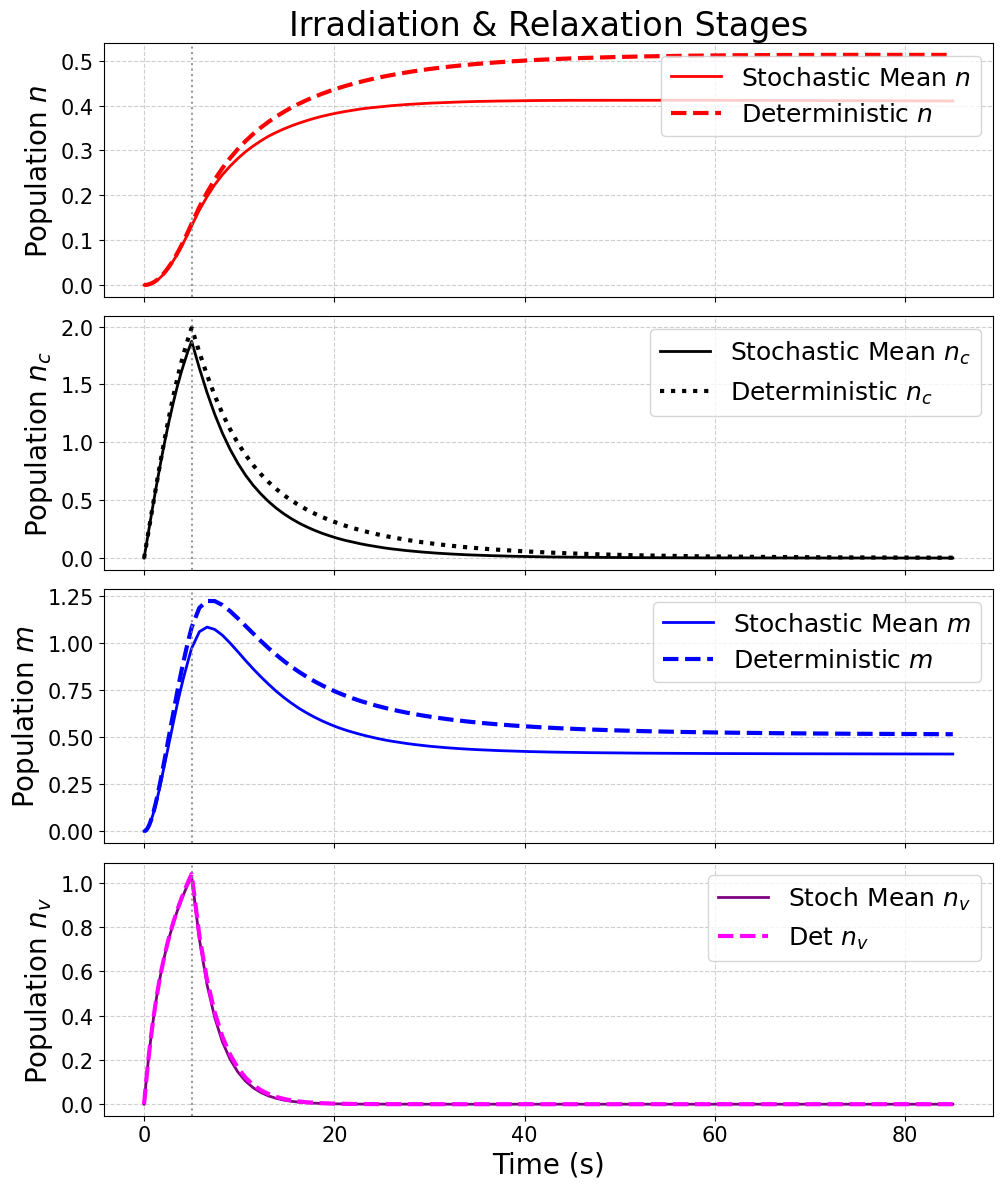

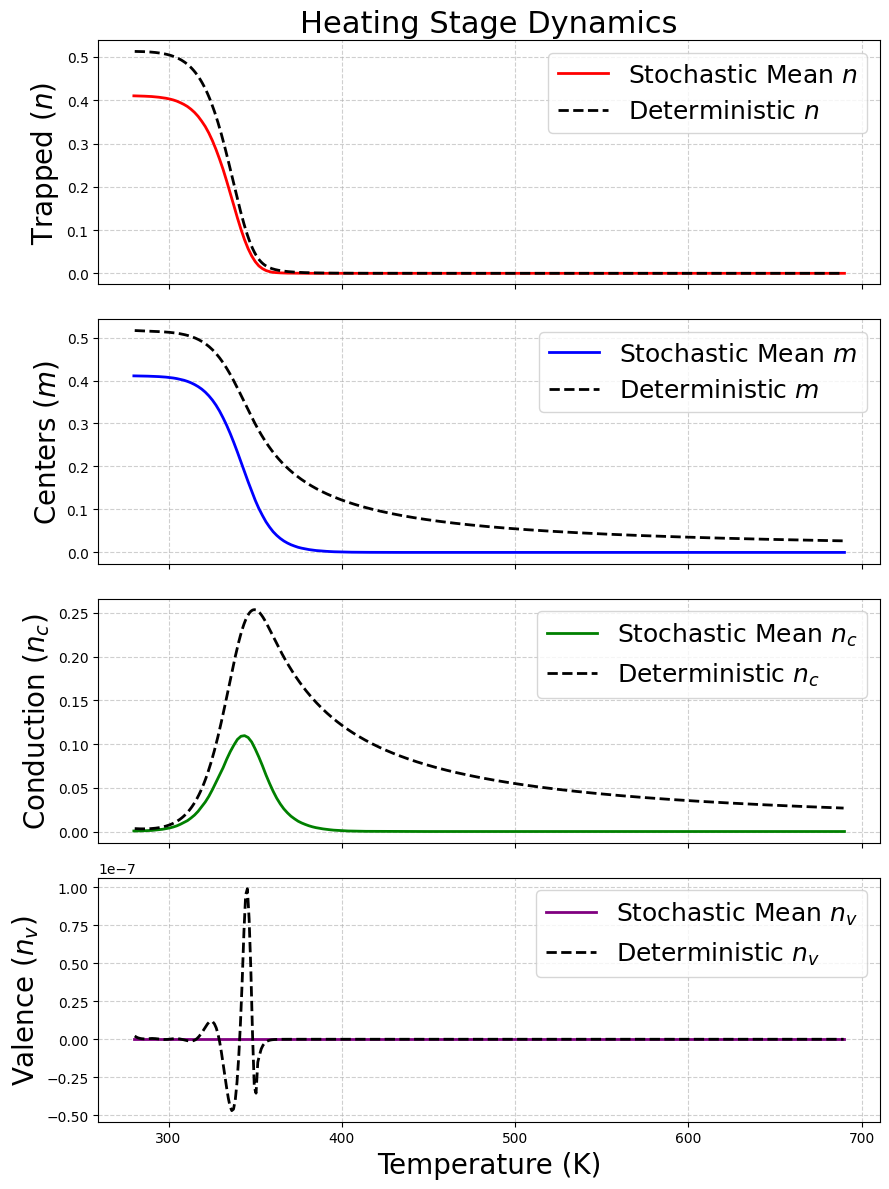

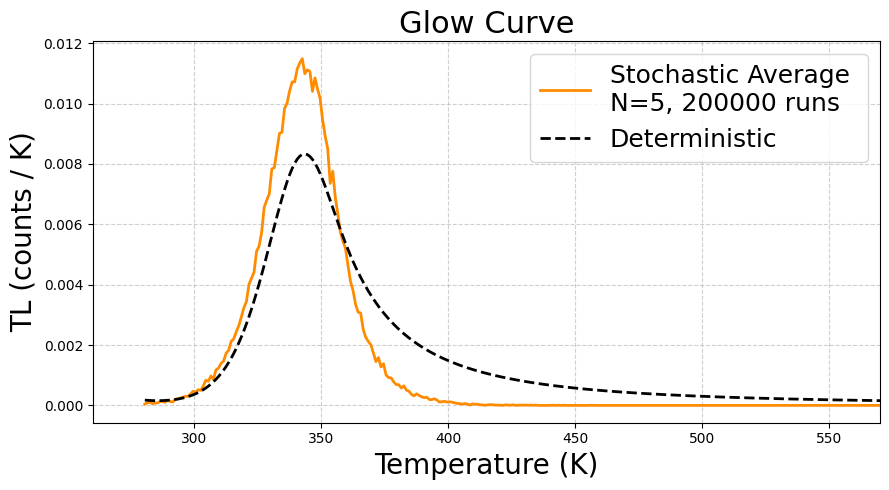

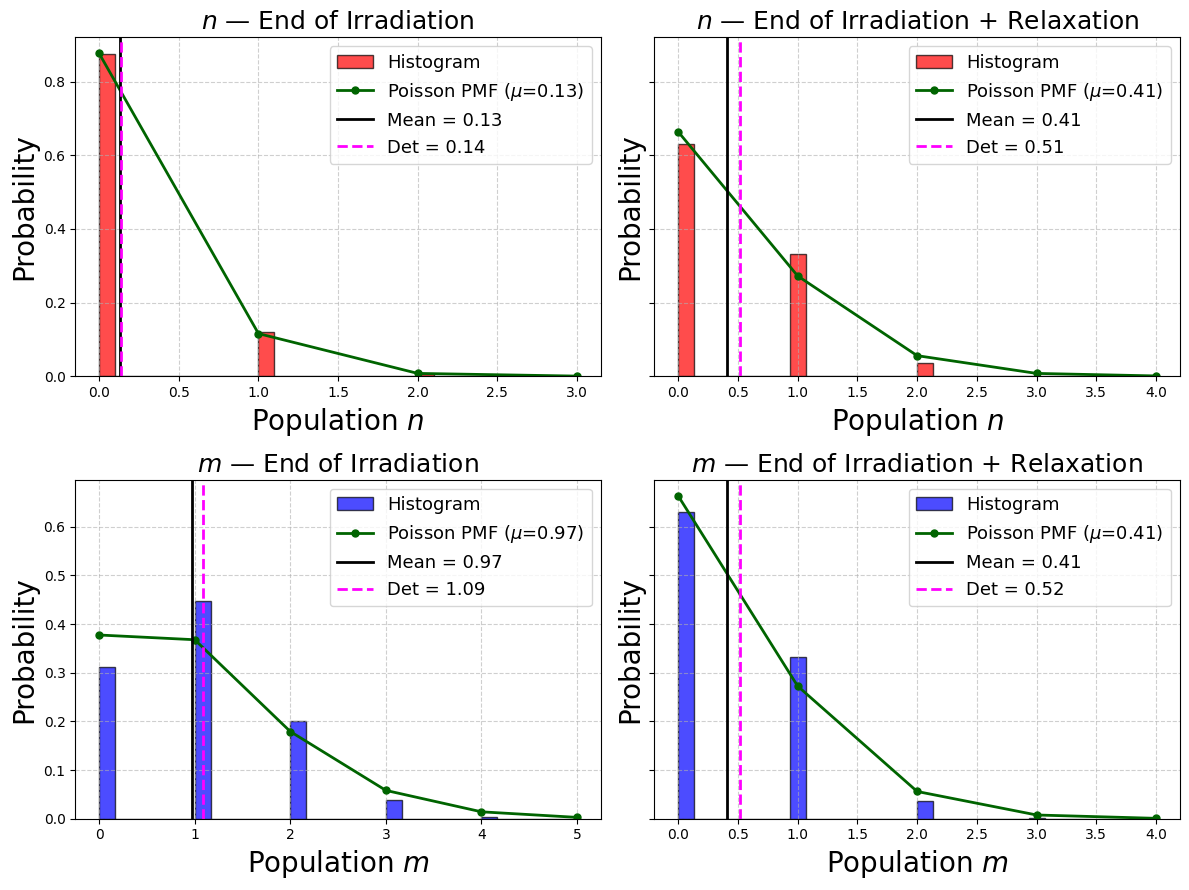

Relative Difference: -16.04%


In [1]:
# <<code2_1_fixed, eval=TRUE,results='hold',echo=TRUE, fig.show='hold',collapse=TRUE,fig.align='center',fig.width=10, out.width='90%',fig.height=12>>=
# #/
# -*- coding: utf-8 -*-
"""
OTOR Model Simulation — Pure Gillespie (direct method)

Phases:
  1) Irradiation (G>0, T=T0)   : constant propensities -> exact Gillespie.
  2) Relaxation  (G=0, T=T0)   : constant propensities -> exact Gillespie.
  3) Heating     (G=0, T=T0+βt): time-dependent a0(t) -> next-event time
                                 found by inverting the integrated hazard
                                 Lambda(tau) = ∫ a0 dt' = -ln(u) via
                                 numerical quadrature + bisection.
"""

import matplotlib.pyplot as plt
from numba import njit
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import poisson
import time

start_time = time.time()

# --- Parameters ---
E   = 0.87
s   = 1e12
N   = 5

Nref = 5
A_n  = 0.005 * Nref / N
A_m  = 0.1   * Nref / N
B_m  = 0.1   * Nref / N
G    = 0.5   * N / Nref

k_B = 8.617333e-5

T0         = 280.0
beta       = 1.0
t_irr      = 5.0
t_relax    = 80.0
t_heat_max = 410.0

num_runs = 200000

# ------------------------------------------------------------------
# Time-dependent hazard helpers (Numba-compiled) — unchanged
# ------------------------------------------------------------------
@njit(cache=True)
def _hazard_increment(t_start, tau, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub):
    if tau <= 0.0:
        return 0.0
    a_const = (A_n * max(0.0, N - n) * nc
               + A_m * max(0.0, m)     * nc
               + B_m * max(0.0, N - m) * nv)
    if n_sub % 2 == 1:
        n_sub += 1
    h = tau / n_sub
    total = 0.0
    for i in range(n_sub + 1):
        tt = t_start + i * h
        T  = T0 + beta * tt
        p  = s * np.exp(-E / (k_B * T))
        val = n * p + a_const
        if i == 0 or i == n_sub:
            w = 1.0
        elif i % 2 == 1:
            w = 4.0
        else:
            w = 2.0
        total += w * val
    return total * h / 3.0


@njit(cache=True)
def _draw_heating_tau(t_start, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                      u, t_heat_max, tol, n_sub):
    target = -np.log(u)
    t_remaining = t_heat_max - t_start
    if t_remaining <= 0.0:
        return 0.0
    full = _hazard_increment(t_start, t_remaining, n, nc, m, nv,
                             A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
    if full < target:
        return t_remaining + 1.0
    lo = 0.0
    hi = t_remaining
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        hmid = _hazard_increment(t_start, mid, n, nc, m, nv,
                                 A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
        if hmid < target:
            lo = mid
        else:
            hi = mid
        if (hi - lo) < tol:
            break
    return 0.5 * (lo + hi)


@njit(cache=True)
def _select_channel(u, a1, a2, a3, a4, a5, a0):
    uu = u * a0
    if uu < a1:
        return 1
    uu -= a1
    if uu < a2:
        return 2
    uu -= a2
    if uu < a3:
        return 3
    uu -= a3
    if uu < a4:
        return 4
    return 5


# ------------------------------------------------------------------
# Simulator — FIXED fill order
# ------------------------------------------------------------------
@njit(cache=True)
def simulate_single_trajectory(
    N, A_n, A_m, B_m, E, s, k_B,
    T0, beta, G,
    t_irr, t_relax, t_heat_max,
):
    irr_times  = np.linspace(0.0, t_irr, 50)
    irr_states = np.zeros((len(irr_times), 4))

    rel_times  = np.linspace(0.0, t_relax, 100)
    rel_states = np.zeros((len(rel_times), 4))

    heat_temps  = np.linspace(T0, T0 + beta * t_heat_max, 200)
    heat_states = np.zeros((len(heat_temps), 4))

    emission_temps_buf = np.empty(N + 50, dtype=np.float64)
    emission_count = 0

    n  = 0.0; nc = 0.0; m = 0.0; nv = 0.0
    p_room = s * np.exp(-E / (k_B * T0))

    # ==================================================================
    # PHASE 1: Irradiation (G>0, T=T0)
    #   FIX: fill grid points in [t, t_next) with PRE-jump state,
    #        then advance t and apply the jump.
    # ==================================================================
    t   = 0.0
    idx = 0
    while t < t_irr:
        a1 = G
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t + tau

        # --- fill [t, t_next) with CURRENT state (correct interval value) ---
        while idx < len(irr_times) and irr_times[idx] < t_next:
            irr_states[idx, 0] = n
            irr_states[idx, 1] = nc
            irr_states[idx, 2] = m
            irr_states[idx, 3] = nv
            idx += 1

        if t_next > t_irr:
            break

        t = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 1:  nc += 1; nv += 1
        elif ch == 2:  n  -= 1; nc += 1
        elif ch == 3:  n  += 1; nc -= 1
        elif ch == 4:  nc -= 1; m  -= 1
        else:          nv -= 1; m  += 1

    # trailing fill: grid points >= last fill (state is constant thereafter)
    while idx < len(irr_times):
        irr_states[idx, 0] = n
        irr_states[idx, 1] = nc
        irr_states[idx, 2] = m
        irr_states[idx, 3] = nv
        idx += 1

    # ==================================================================
    # PHASE 2: Relaxation (G=0, T=T0)  — same fix
    # ==================================================================
    t_rel = 0.0
    idx   = 0
    while t_rel < t_relax:
        a1 = 0.0
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t_rel + tau

        # --- fill [t_rel, t_next) with CURRENT state ---
        while idx < len(rel_times) and rel_times[idx] < t_next:
            rel_states[idx, 0] = n
            rel_states[idx, 1] = nc
            rel_states[idx, 2] = m
            rel_states[idx, 3] = nv
            idx += 1

        if t_next > t_relax:
            break

        t_rel = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 2:  n  -= 1; nc += 1
        elif ch == 3:  n  += 1; nc -= 1
        elif ch == 4:  nc -= 1; m  -= 1
        else:          nv -= 1; m  += 1

    while idx < len(rel_times):
        rel_states[idx, 0] = n
        rel_states[idx, 1] = nc
        rel_states[idx, 2] = m
        rel_states[idx, 3] = nv
        idx += 1

    # ==================================================================
    # PHASE 3: Heating — time-dependent.  Same fix, grid in TEMPERATURE.
    #   Fill [t_heat, t_heat+tau) with pre-jump state (mapped to T).
    # ==================================================================
    t_heat = 0.0
    idx    = 0
    tol    = 1e-9
    n_sub  = 16

    while t_heat < t_heat_max and (n > 0 or nc > 0 or nv > 0 or m > 0):
        T_now = T0 + beta * t_heat
        p_now = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        u   = np.random.uniform(0.0, 1.0)
        tau = _draw_heating_tau(t_heat, n, nc, m, nv,
                                A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                                u, t_heat_max, tol, n_sub)
        if t_heat + tau > t_heat_max or tau > (t_heat_max - t_heat):
            # no event before heating ends
            t_next = t_heat_max
        else:
            t_next = t_heat + tau

        # --- fill [t_heat, t_next) with CURRENT state, mapped to T ---
        T_next = T0 + beta * t_next
        while idx < len(heat_temps) and heat_temps[idx] < T_next:
            heat_states[idx, 0] = n
            heat_states[idx, 1] = nc
            heat_states[idx, 2] = m
            heat_states[idx, 3] = nv
            idx += 1

        if t_next >= t_heat_max:
            t_heat = t_heat_max
            break

        t_heat = t_next
        T_now  = T0 + beta * t_heat
        p_now  = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, 0.0, a0)
        if   ch == 1:  n  -= 1; nc += 1
        elif ch == 2:  n  += 1; nc -= 1
        elif ch == 3:
            nc -= 1; m  -= 1
            if emission_count < len(emission_temps_buf):
                emission_temps_buf[emission_count] = T_now
                emission_count += 1
        else:          nv -= 1; m  += 1

    while idx < len(heat_temps):
        heat_states[idx, 0] = n
        heat_states[idx, 1] = nc
        heat_states[idx, 2] = m
        heat_states[idx, 3] = nv
        idx += 1

    return irr_states, rel_states, heat_states, emission_temps_buf[:emission_count]


# ----------------------------------------------------------------------
# Warm-up JIT
# ----------------------------------------------------------------------
np.random.seed(42)
_ = simulate_single_trajectory(N, A_n, A_m, B_m, E, s, k_B,
                               T0, beta, G, t_irr, t_relax, t_heat_max)

bin_width   = 1.0
bins        = np.arange(T0, T0 + beta * t_heat_max + bin_width, bin_width)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

all_irr_states   = []
all_rel_states   = []
all_heat_states  = []
all_intensities  = []
irr_end_states   = np.zeros((num_runs, 4))
rel_end_states   = np.zeros((num_runs, 4))

irr_times  = np.linspace(0.0, t_irr, 50)
rel_times  = np.linspace(0.0, t_relax, 100)
heat_temps = np.linspace(T0, T0 + beta * t_heat_max, 200)
print_interval = max(num_runs // 4, 1)

for i in range(num_runs):
    irr_st, rel_st, heat_st, event_temps = simulate_single_trajectory(
        N, A_n, A_m, B_m, E, s, k_B,
        T0, beta, G, t_irr, t_relax, t_heat_max)
    all_irr_states.append(irr_st)
    all_rel_states.append(rel_st)
    all_heat_states.append(heat_st)
    hist, _ = np.histogram(event_temps, bins=bins)
    all_intensities.append(hist / bin_width)
    irr_end_states[i, :] = irr_st[-1, :]
    rel_end_states[i, :] = rel_st[-1, :]
    if (i + 1) % print_interval == 0 or (i + 1) == num_runs:
        print(f"    {i + 1}/{num_runs} runs. Elapsed: {time.time()-start_time:.2f} s")

mean_irr       = np.mean(all_irr_states,  axis=0)
mean_rel       = np.mean(all_rel_states,  axis=0)
mean_heat      = np.mean(all_heat_states, axis=0)
mean_intensity = np.mean(all_intensities, axis=0)

rel_times_full = rel_times + t_irr
full_times     = np.concatenate([irr_times, rel_times_full[1:]])
full_states    = np.concatenate([mean_irr, mean_rel[1:]], axis=0)

# ----------------------------------------------------------------------
# Deterministic macroscopic solution (unchanged)
# ----------------------------------------------------------------------
p_room_det = s * np.exp(-E / (k_B * T0))

def ode_irr(t, y):
    n, nc, m, nv = y
    dn  = -n * p_room_det + A_n * max(0.0, N - n) * nc
    dnc = G - n * p_room_det - A_n * max(0.0, N - n) * nc - A_m * max(0.0, m) * nc
    dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N - m) * nv
    dnv = G - B_m * max(0.0, N - m) * nv
    return [dn, dnc, dm, dnv]

def ode_relax(t, y):
    n, nc, m, nv = y
    dn  = -n * p_room_det + A_n * max(0.0, N - n) * nc
    dnc = n * p_room_det - A_n * max(0.0, N - n) * nc - A_m * max(0.0, m) * nc
    dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N - m) * nv
    dnv = -B_m * max(0.0, N - m) * nv
    return [dn, dnc, dm, dnv]

def ode_heat(t, y):
    n, nc, m, nv = y
    T = T0 + beta * t
    p = s * np.exp(-E / (k_B * T))
    dn  = -n * p + A_n * max(0.0, N - n) * nc
    dnc = n * p - A_n * max(0.0, N - n) * nc - A_m * max(0.0, m) * nc
    dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N - m) * nv
    dnv = -B_m * max(0.0, N - m) * nv
    return [dn, dnc, dm, dnv]

sol_irr   = solve_ivp(ode_irr,   [0, t_irr],      [0.0]*4, method='LSODA')
y0_relax  = sol_irr.y[:, -1]
sol_relax = solve_ivp(ode_relax, [0, t_relax],    y0_relax, method='LSODA')
y0_heat   = sol_relax.y[:, -1]

sol_irr_eval   = solve_ivp(ode_irr,   [0, t_irr],   [0.0]*4,
                           t_eval=irr_times, method='LSODA')
sol_relax_eval = solve_ivp(ode_relax, [0, t_relax], y0_relax,
                           t_eval=rel_times, method='LSODA')
det_times_full  = np.concatenate([irr_times, rel_times[1:] + t_irr])
det_states_full = np.concatenate([sol_irr_eval.y.T, sol_relax_eval.y.T[1:]], axis=0)

t_bin_eval = np.clip((bin_centers - T0) / beta, 0, t_heat_max)
sol_heat_bins = solve_ivp(ode_heat, [0, t_heat_max], y0_heat,
                          t_eval=t_bin_eval, method='LSODA')
det_intensity_bins = np.array([
    A_m * max(0.0, m_val) * max(0.0, nc_val)
    for n_val, nc_val, m_val, nv_val in sol_heat_bins.y.T
])

stoch_area = np.sum(mean_intensity * bin_width)
det_area   = np.sum(det_intensity_bins * bin_width)
diff_pct   = 100 * (stoch_area - det_area) / det_area

print('\n' + '=' * 50)
print('GLOW CURVE AREA COMPARISON (Evaluated on Identical Bins)')
print('=' * 50)
print(f'Stochastic Area: {stoch_area:.4f}')
print(f'Deterministic Area: {det_area:.4f}')
print(f'Relative Difference: {diff_pct:.2f}%')
print('=' * 50)

# ============================================================================
# PLOTS
# ============================================================================
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
axes[0].plot(full_times, full_states[:, 0], 'r-',  lw=2, label='Stochastic Mean $n$')
axes[0].plot(det_times_full, det_states_full[:, 0], 'r--', lw=3, label='Deterministic $n$')
axes[0].axvline(t_irr, color='gray', linestyle=':', alpha=0.8)
axes[0].set_ylabel('Population $n$', fontsize=20)
axes[0].set_title('Irradiation & Relaxation Stages', fontsize=24)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(frameon=True, fontsize=18, loc='upper right')

axes[1].plot(full_times, full_states[:, 1], 'k-', lw=2, label='Stochastic Mean $n_c$')
axes[1].plot(det_times_full, det_states_full[:, 1], 'k:', lw=3, label='Deterministic $n_c$')
axes[1].axvline(t_irr, color='gray', linestyle=':', alpha=0.8)
axes[1].set_ylabel('Population $n_c$', fontsize=20)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(frameon=True, fontsize=18, loc='upper right')

axes[2].plot(full_times, full_states[:, 2], 'b-',  lw=2, label='Stochastic Mean $m$')
axes[2].plot(det_times_full, det_states_full[:, 2], 'b--', lw=3, label='Deterministic $m$')
axes[2].axvline(t_irr, color='gray', linestyle=':', alpha=0.8)
axes[2].set_ylabel('Population $m$', fontsize=20)
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].legend(frameon=True, fontsize=18, loc='upper right')

axes[3].plot(full_times, full_states[:, 3], color='purple', lw=2, label='Stoch Mean $n_v$')
axes[3].plot(det_times_full, det_states_full[:, 3], color='magenta',
             linestyle='--', lw=3, label='Det $n_v$')
axes[3].axvline(t_irr, color='gray', linestyle=':', alpha=0.8)
axes[3].set_xlabel('Time (s)', fontsize=20)
axes[3].set_ylabel('Population $n_v$', fontsize=20)
axes[3].grid(True, linestyle='--', alpha=0.6)
axes[3].legend(frameon=True, fontsize=18, loc='best')

for ax in axes:
    ax.tick_params(axis='both', which='major', labelsize=15)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 1, figsize=(9, 12), sharex=True)
axes[0].plot(heat_temps, mean_heat[:, 0], color='red',  lw=2, label='Stochastic Mean $n$')
axes[0].plot(bin_centers, sol_heat_bins.y[0], color='black', linestyle='--', lw=2, label='Deterministic $n$')
axes[0].set_ylabel('Trapped ($n$)', fontsize=20)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(frameon=True, fontsize=18)
axes[0].set_title('Heating Stage Dynamics', fontsize=22)

axes[1].plot(heat_temps, mean_heat[:, 2], color='blue',  lw=2, label='Stochastic Mean $m$')
axes[1].plot(bin_centers, sol_heat_bins.y[2], color='black', linestyle='--', lw=2, label='Deterministic $m$')
axes[1].set_ylabel('Centers ($m$)', fontsize=20)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(frameon=True, fontsize=18)

axes[2].plot(heat_temps, mean_heat[:, 1], color='green', lw=2, label='Stochastic Mean $n_c$')
axes[2].plot(bin_centers, sol_heat_bins.y[1], color='black', linestyle='--', lw=2, label='Deterministic $n_c$')
axes[2].set_ylabel('Conduction ($n_c$)', fontsize=20)
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].legend(frameon=True, fontsize=18)

axes[3].plot(heat_temps, mean_heat[:, 3], color='purple', lw=2, label='Stochastic Mean $n_v$')
axes[3].plot(bin_centers, sol_heat_bins.y[3], color='black', linestyle='--', lw=2, label='Deterministic $n_v$')
axes[3].set_xlabel('Temperature (K)', fontsize=20)
axes[3].set_ylabel('Valence ($n_v$)', fontsize=20)
axes[3].grid(True, linestyle='--', alpha=0.6)
axes[3].legend(frameon=True, fontsize=18)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(bin_centers, mean_intensity,
         color='darkorange', lw=2,
         label=f'Stochastic Average \nN={N}, {num_runs} runs')
plt.plot(bin_centers, det_intensity_bins,
         color='black', linestyle='--', lw=2, label='Deterministic')
plt.xlabel('Temperature (K)', fontsize=20)
plt.ylabel('TL (counts / K)', fontsize=20)
plt.title('Glow Curve', fontsize=22)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, fontsize=18)
plt.xlim(260, 570)
plt.tight_layout()
plt.show()

# ============================================================================
# Combined 2x2 histograms: n and m at end of irradiation / relaxation
# ============================================================================
det_vals_irr = sol_irr.y[:, -1]
det_vals_rel = sol_relax.y[:, -1]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey='row')
state_idx  = [0, 2]
row_labels = [r'$n$', r'$m$']
col_titles = ['End of Irradiation', 'End of Irradiation + Relaxation']
col_data   = [irr_end_states, rel_end_states]
col_det    = [det_vals_irr,   det_vals_rel]
colors     = {0: 'red', 2: 'blue'}

for row, (idx, rlab) in enumerate(zip(state_idx, row_labels)):
    for col in range(2):
        ax     = axes[row, col]
        data   = col_data[col][:, idx]
        mu     = data.mean()
        n_data = len(data)
        weights = np.ones(n_data) / n_data
        ax.hist(data, bins=30, weights=weights, density=False,
                color=colors[idx], alpha=0.7, edgecolor='black',
                label='Histogram')
        k_min  = int(max(0, np.floor(data.min())))
        k_max  = int(np.ceil(data.max()))
        k_vals = np.arange(k_min, k_max + 1)
        pmf    = poisson.pmf(k_vals, mu)
        ax.plot(k_vals, pmf, 'o-', color='darkgreen', lw=2, ms=5,
                label=f'Poisson PMF ($\\mu$={mu:.2f})')
        ax.axvline(mu, color='black', linestyle='-', lw=2,
                   label=f'Mean = {mu:.2f}')
        ax.axvline(col_det[col][idx], color='magenta', linestyle='--',
                   lw=2, label=f'Det = {col_det[col][idx]:.2f}')
        ax.set_xlabel(f'Population {rlab}', fontsize=20)
        ax.set_ylabel('Probability', fontsize=20)
        ax.set_title(f'{rlab} — {col_titles[col]}', fontsize=18)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(frameon=True, fontsize=13)

plt.tight_layout()
plt.show()
print(f'Relative Difference: {diff_pct:.2f}%')

# ============================================================================
# SAVE DATA
# ============================================================================
save_dict = {
    'N': np.array(N), 'num_runs': np.array(num_runs),
    'T0': np.array(T0), 'beta': np.array(beta),
    't_irr': np.array(t_irr), 't_relax': np.array(t_relax),
    't_heat_max': np.array(t_heat_max), 'bin_width': np.array(bin_width),
    'full_times': full_times, 'full_states': full_states,
    'det_times_full': det_times_full, 'det_states_full': det_states_full,
    'heat_temps': heat_temps, 'mean_heat': mean_heat,
    'bin_centers': bin_centers, 'sol_heat_bins_y': sol_heat_bins.y,
    'mean_intensity': mean_intensity,
    'det_intensity_bins': det_intensity_bins,
    'irr_end_states': irr_end_states, 'det_vals_irr': sol_irr.y[:, -1],
    'rel_end_states': rel_end_states, 'det_vals_rel': sol_relax.y[:, -1],
}
# np.savez('otor_sim_fixed.npz', **save_dict)


RUNNING SIMULATION FOR N = 5
  N=5: using num_runs=20000
  N=5: 5000/20000 runs. Elapsed: 3.74 s
  N=5: 10000/20000 runs. Elapsed: 4.12 s
  N=5: 15000/20000 runs. Elapsed: 4.46 s
  N=5: 20000/20000 runs. Elapsed: 4.97 s
  N=5: Stoch Area=0.4127, Det Area=0.4893, Rel Diff=-15.65%

Relative Difference for N = 5: -15.65%


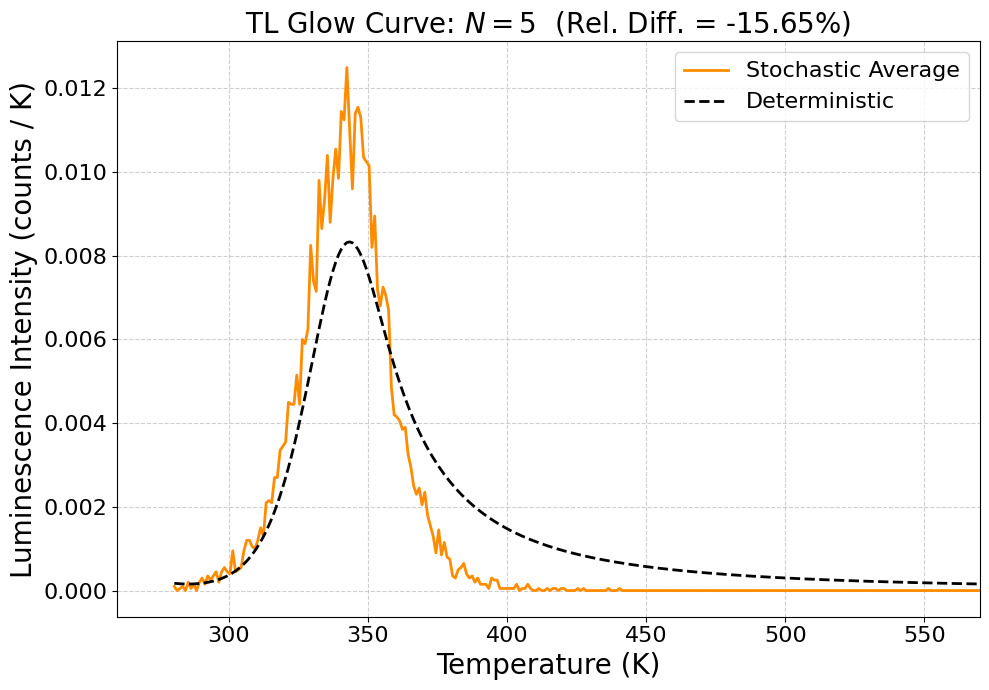

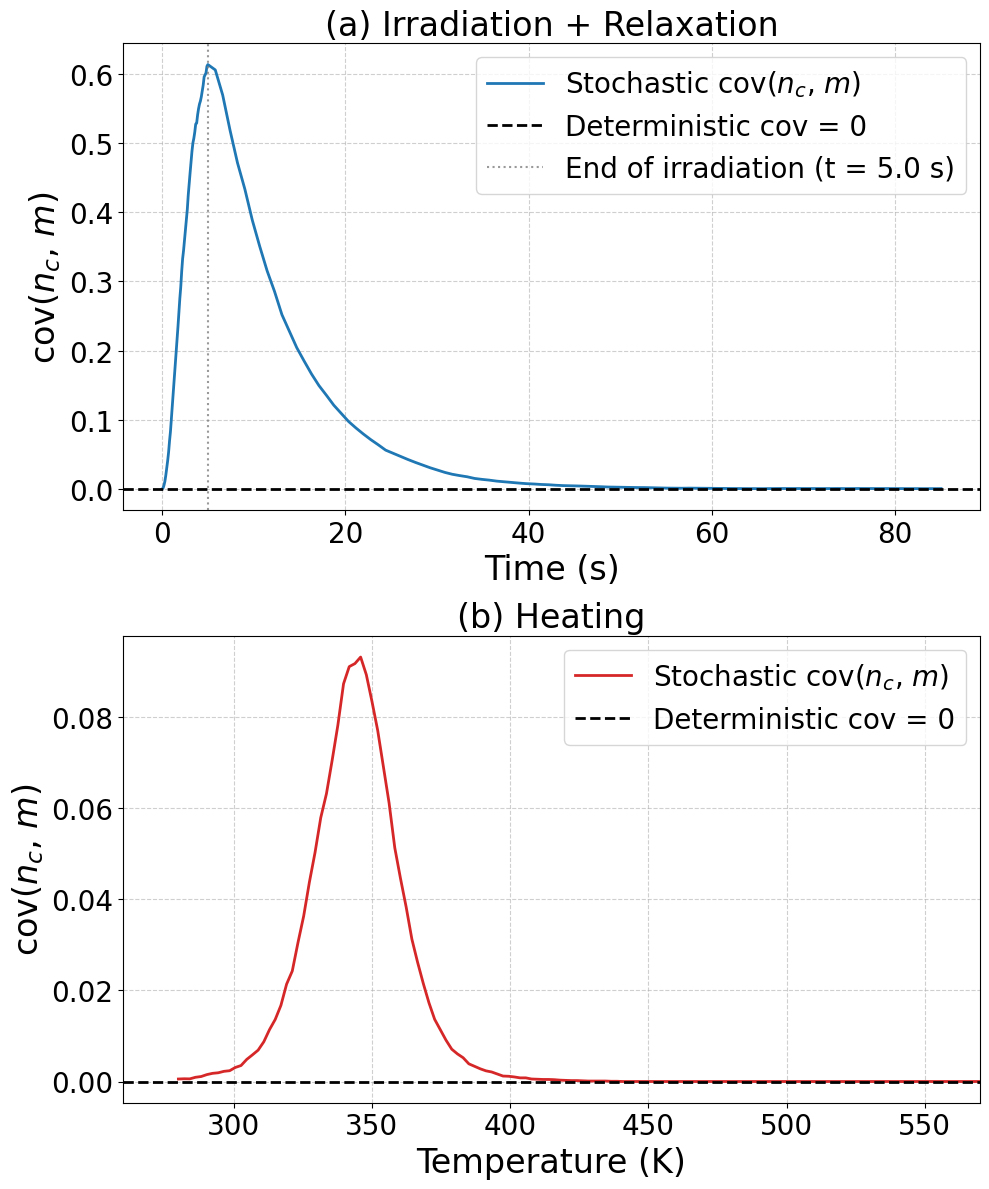

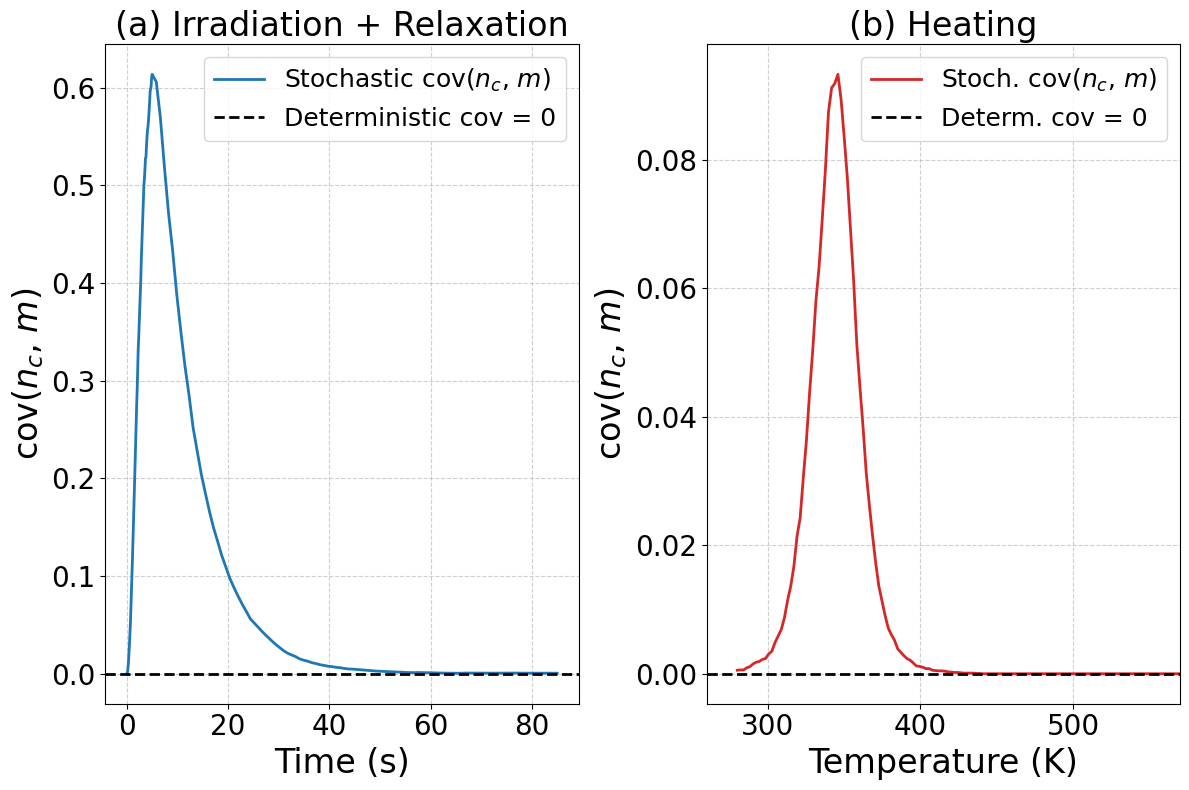


Total elapsed time: 8.52 s


In [2]:
# -*- coding: utf-8 -*-
"""
OTOR Model Simulation with Valence Band Hole Dynamics (nv), Hole Capture (Bm),
and Total Recombination Center Capacity M = N.

*** Direct Gillespie (no dt_micro) ***
  Phases 1 & 2 : constant propensities -> tau = -ln(u)/a0  (exact)
  Phase 3      : time-dependent a0(t)   -> tau from inverting
                 Lambda(tau) = ∫ a0 dt = -ln(u)  via Simpson + bisection

Also: fill-order fix (fill [t, t_next) with pre-jump state before jumping).

Runs for N = 5, plots stochastic vs deterministic TL glow curves
and covariance cov(nc, m) during irradiation, relaxation, and heating.
"""

import matplotlib.pyplot as plt
from numba import njit
import numpy as np
from scipy.integrate import solve_ivp
import time

start_time = time.time()

# --- Fixed Physical Constants ---
Nref = 5
E    = 0.87
s    = 1e12
k_B  = 8.617333e-5

# --- Fixed Protocol Parameters ---
T0         = 280.0
beta       = 1.0
t_irr      = 5.0
t_relax    = 80.0
t_heat_max = 410.0


# ============================================================================
# Time-dependent hazard helpers (Numba) — for Phase 3
# ============================================================================
@njit(cache=True)
def _hazard_increment(t_start, tau, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub):
    """∫_0^tau a0(t_start+s) ds via composite Simpson."""
    if tau <= 0.0:
        return 0.0
    a_const = (A_n * max(0.0, N - n) * nc
               + A_m * max(0.0, m)     * nc
               + B_m * max(0.0, N - m) * nv)
    if n_sub % 2 == 1:
        n_sub += 1
    h = tau / n_sub
    total = 0.0
    for i in range(n_sub + 1):
        tt = t_start + i * h
        T  = T0 + beta * tt
        p  = s * np.exp(-E / (k_B * T))
        val = n * p + a_const
        if i == 0 or i == n_sub:
            w = 1.0
        elif i % 2 == 1:
            w = 4.0
        else:
            w = 2.0
        total += w * val
    return total * h / 3.0


@njit(cache=True)
def _draw_heating_tau(t_start, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                      u, t_heat_max, tol, n_sub):
    """Find tau >= 0 s.t. ∫_0^tau a0(t_start+s) ds = -ln(u)."""
    target = -np.log(u)
    t_remaining = t_heat_max - t_start
    if t_remaining <= 0.0:
        return 0.0
    full = _hazard_increment(t_start, t_remaining, n, nc, m, nv,
                             A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
    if full < target:
        return t_remaining + 1.0   # no event before end
    lo = 0.0
    hi = t_remaining
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        hmid = _hazard_increment(t_start, mid, n, nc, m, nv,
                                 A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
        if hmid < target:
            lo = mid
        else:
            hi = mid
        if (hi - lo) < tol:
            break
    return 0.5 * (lo + hi)


@njit(cache=True)
def _select_channel(u, a1, a2, a3, a4, a5, a0):
    uu = u * a0
    if uu < a1:
        return 1
    uu -= a1
    if uu < a2:
        return 2
    uu -= a2
    if uu < a3:
        return 3
    uu -= a3
    if uu < a4:
        return 4
    return 5


# ============================================================================
# Direct-Gillespie simulator (no dt_micro), with fill-order fix
# ============================================================================
@njit(cache=True)
def simulate_single_trajectory(
    N, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
    t_irr, t_relax, t_heat_max,
):
    irr_times   = np.linspace(0.0, t_irr, 50)
    irr_states  = np.zeros((len(irr_times), 4))

    rel_times   = np.linspace(0.0, t_relax, 100)
    rel_states  = np.zeros((len(rel_times), 4))

    heat_temps  = np.linspace(T0, T0 + beta * t_heat_max, 200)
    heat_states = np.zeros((len(heat_temps), 4))

    emission_temps_buf = np.empty(N * 4 + 200, dtype=np.float64)
    emission_count = 0

    n = 0.0; nc = 0.0; m = 0.0; nv = 0.0
    p_room = s * np.exp(-E / (k_B * T0))

    # ------------------------------------------------------------------
    # PHASE 1: Irradiation (G>0, T=T0) — constant propensities
    # ------------------------------------------------------------------
    t   = 0.0
    idx = 0
    while t < t_irr:
        a1 = G
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t + tau

        # fill [t, t_next) with CURRENT (pre-jump) state
        while idx < len(irr_times) and irr_times[idx] < t_next:
            irr_states[idx, 0] = n
            irr_states[idx, 1] = nc
            irr_states[idx, 2] = m
            irr_states[idx, 3] = nv
            idx += 1

        if t_next > t_irr:
            break

        t = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 1: nc += 1; nv += 1        # pair creation
        elif ch == 2: n  -= 1; nc += 1        # thermal emission
        elif ch == 3: n  += 1; nc -= 1        # retrapping
        elif ch == 4: nc -= 1; m  -= 1        # recombination
        else:         nv -= 1; m  += 1        # hole capture

    while idx < len(irr_times):
        irr_states[idx, 0] = n; irr_states[idx, 1] = nc
        irr_states[idx, 2] = m; irr_states[idx, 3] = nv
        idx += 1

    # ------------------------------------------------------------------
    # PHASE 2: Relaxation (G=0, T=T0) — constant propensities
    # ------------------------------------------------------------------
    t_rel = 0.0
    idx   = 0
    while t_rel < t_relax:
        a1 = 0.0
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t_rel + tau

        while idx < len(rel_times) and rel_times[idx] < t_next:
            rel_states[idx, 0] = n; rel_states[idx, 1] = nc
            rel_states[idx, 2] = m; rel_states[idx, 3] = nv
            idx += 1

        if t_next > t_relax:
            break

        t_rel = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 2: n  -= 1; nc += 1
        elif ch == 3: n  += 1; nc -= 1
        elif ch == 4: nc -= 1; m  -= 1
        else:         nv -= 1; m  += 1

    while idx < len(rel_times):
        rel_states[idx, 0] = n; rel_states[idx, 1] = nc
        rel_states[idx, 2] = m; rel_states[idx, 3] = nv
        idx += 1

    # ------------------------------------------------------------------
    # PHASE 3: Heating — time-dependent a0(t), hazard inversion
    # ------------------------------------------------------------------
    t_heat = 0.0
    idx    = 0
    tol    = 1e-9
    n_sub  = 16

    while t_heat < t_heat_max and (n > 0 or nc > 0 or nv > 0 or m > 0):
        T_now = T0 + beta * t_heat
        p_now = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        u   = np.random.uniform(0.0, 1.0)
        tau = _draw_heating_tau(t_heat, n, nc, m, nv,
                                A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                                u, t_heat_max, tol, n_sub)
        if t_heat + tau > t_heat_max or tau > (t_heat_max - t_heat):
            t_next = t_heat_max
        else:
            t_next = t_heat + tau

        # fill [t_heat, t_next) with CURRENT state, mapped to T
        T_next = T0 + beta * t_next
        while idx < len(heat_temps) and heat_temps[idx] < T_next:
            heat_states[idx, 0] = n; heat_states[idx, 1] = nc
            heat_states[idx, 2] = m; heat_states[idx, 3] = nv
            idx += 1

        if t_next >= t_heat_max:
            t_heat = t_heat_max
            break

        t_heat = t_next
        T_now  = T0 + beta * t_heat
        p_now  = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, 0.0, a0)
        if   ch == 1: n  -= 1; nc += 1        # thermal emission
        elif ch == 2: n  += 1; nc -= 1        # retrapping
        elif ch == 3:                         # recombination (TL photon)
            nc -= 1; m  -= 1
            if emission_count < len(emission_temps_buf):
                emission_temps_buf[emission_count] = T_now
                emission_count += 1
        else:         nv -= 1; m  += 1        # hole capture

    while idx < len(heat_temps):
        heat_states[idx, 0] = n; heat_states[idx, 1] = nc
        heat_states[idx, 2] = m; heat_states[idx, 3] = nv
        idx += 1

    return (irr_states, rel_states, heat_states,
            emission_temps_buf[:emission_count])


# ============================================================================
# Simulation driver
# ============================================================================
def run_simulation(N_val, seed=42):
    base_runs = 20000
    num_runs  = max(int(round(base_runs * Nref / N_val)), 100)

    A_n = 0.005 * Nref / N_val
    A_m = 0.1   * Nref / N_val
    B_m = 0.1   * Nref / N_val
    G   = 0.5   * N_val / Nref

    np.random.seed(seed)

    bin_width   = 1.0
    bins        = np.arange(T0, T0 + beta * t_heat_max + bin_width, bin_width)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    # Warm-up JIT
    _ = simulate_single_trajectory(
        N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
        t_irr, t_relax, t_heat_max)

    print(f"  N={N_val}: using num_runs={num_runs}")

    # --- Accumulators: means AND second moments for covariance ---
    irr_nc_sum = irr_m_sum = irr_nc_m_sum = None
    rel_nc_sum = rel_m_sum = rel_nc_m_sum = None
    heat_nc_sum = heat_m_sum = heat_nc_m_sum = None

    all_intensities = []
    print_interval = max(num_runs // 4, 1)

    for i in range(num_runs):
        irr_s, rel_s, heat_s, event_temps = simulate_single_trajectory(
            N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
            t_irr, t_relax, t_heat_max)

        hist, _ = np.histogram(event_temps, bins=bins)
        all_intensities.append(hist / bin_width)

        if irr_nc_sum is None:
            sh = irr_s[:, 1].shape
            irr_nc_sum   = np.zeros(sh); irr_m_sum   = np.zeros(sh)
            irr_nc_m_sum = np.zeros(sh)
            rel_nc_sum   = np.zeros(rel_s[:, 1].shape)
            rel_m_sum    = np.zeros(rel_s[:, 1].shape)
            rel_nc_m_sum = np.zeros(rel_s[:, 1].shape)
            heat_nc_sum   = np.zeros(heat_s[:, 1].shape)
            heat_m_sum    = np.zeros(heat_s[:, 1].shape)
            heat_nc_m_sum = np.zeros(heat_s[:, 1].shape)

        irr_nc_sum   += irr_s[:, 1];  irr_m_sum   += irr_s[:, 2]
        irr_nc_m_sum += irr_s[:, 1] * irr_s[:, 2]
        rel_nc_sum   += rel_s[:, 1];  rel_m_sum   += rel_s[:, 2]
        rel_nc_m_sum += rel_s[:, 1] * rel_s[:, 2]
        heat_nc_sum   += heat_s[:, 1]; heat_m_sum   += heat_s[:, 2]
        heat_nc_m_sum += heat_s[:, 1] * heat_s[:, 2]

        if (i + 1) % print_interval == 0 or (i + 1) == num_runs:
            print(f"  N={N_val}: {i + 1}/{num_runs} runs. "
                  f"Elapsed: {time.time()-start_time:.2f} s")

    mean_intensity = np.mean(all_intensities, axis=0)

    irr_nc  = irr_nc_sum  / num_runs
    irr_m   = irr_m_sum   / num_runs
    rel_nc  = rel_nc_sum  / num_runs
    rel_m   = rel_m_sum   / num_runs
    heat_nc = heat_nc_sum / num_runs
    heat_m  = heat_m_sum  / num_runs

    # cov(nc, m) = E[nc*m] - E[nc]*E[m]
    irr_cov  = irr_nc_m_sum  / num_runs - irr_nc  * irr_m
    rel_cov  = rel_nc_m_sum  / num_runs - rel_nc  * rel_m
    heat_cov = heat_nc_m_sum / num_runs - heat_nc * heat_m

    # ---------------- Deterministic ODE ----------------
    p_room_det = s * np.exp(-E / (k_B * T0))

    def ode_irr(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (G - n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = G - B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    def ode_relax(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    def ode_heat(t, y):
        n, nc, m, nv = y
        T = T0 + beta * t
        p = s * np.exp(-E / (k_B * T))
        dn  = -n * p + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    sol_irr   = solve_ivp(ode_irr,   [0, t_irr],   [0.0]*4, method='LSODA')
    y0_relax  = sol_irr.y[:, -1]
    sol_relax = solve_ivp(ode_relax, [0, t_relax], y0_relax, method='LSODA')
    y0_heat   = sol_relax.y[:, -1]

    t_bin_eval    = np.clip((bin_centers - T0) / beta, 0, t_heat_max)
    sol_heat_bins = solve_ivp(ode_heat, [0, t_heat_max], y0_heat,
                              t_eval=t_bin_eval, method='LSODA')
    det_intensity_bins = np.array([
        A_m * max(0.0, m_val) * max(0.0, nc_val)
        for n_val, nc_val, m_val, nv_val in sol_heat_bins.y.T
    ])

    stoch_area = np.sum(mean_intensity * bin_width)
    det_area   = np.sum(det_intensity_bins * bin_width)
    diff_pct   = 100 * (stoch_area - det_area) / det_area

    print(f"  N={N_val}: Stoch Area={stoch_area:.4f}, "
          f"Det Area={det_area:.4f}, Rel Diff={diff_pct:.2f}%")

    return (bin_centers, mean_intensity, det_intensity_bins, diff_pct,
            irr_cov, rel_cov, heat_cov)


# ============================================================================
# Run for N = 5
# ============================================================================
N_val = 5
print('\n' + '=' * 60)
print(f'RUNNING SIMULATION FOR N = {N_val}')
print('=' * 60)

(bin_centers, mean_intensity, det_intensity_bins, diff_pct,
 irr_cov, rel_cov, heat_cov) = run_simulation(N_val, seed=42)

print('\n' + '=' * 60)
print(f'Relative Difference for N = {N_val}: {diff_pct:.2f}%')
print('=' * 60)

# ---- Axes for covariance plots ----
irr_times      = np.linspace(0.0, t_irr, 50)
rel_times      = np.linspace(0.0, t_relax, 100)
heat_temps     = np.linspace(T0, T0 + beta * t_heat_max, 200)

rel_times_full    = rel_times + t_irr
cov_irr_rel_time  = np.concatenate([irr_times, rel_times_full])
cov_irr_rel       = np.concatenate([irr_cov,   rel_cov])

# ============================================================================
# Plot 1: TL glow curve
# ============================================================================
fig1, ax1 = plt.subplots(figsize=(10, 7))
ax1.plot(bin_centers, mean_intensity, color='darkorange', lw=2,
         label='Stochastic Average')
ax1.plot(bin_centers, det_intensity_bins, color='black', linestyle='--',
         lw=2, label='Deterministic')
ax1.set_xlabel('Temperature (K)', fontsize=20)
ax1.set_ylabel('Luminescence Intensity (counts / K)', fontsize=20)
ax1.set_title(f'TL Glow Curve: $N={N_val}$  (Rel. Diff. = {diff_pct:.2f}%)',
              fontsize=20)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(frameon=True, fontsize=16)
ax1.set_xlim(260, 570)
ax1.tick_params(axis='both', labelsize=16)
plt.tight_layout()
plt.savefig(f'tl_glow_curve_N{N_val}.png', dpi=150)
plt.show()

# ============================================================================
# Combined Plot (stacked): cov(nc, m)
# ============================================================================
fig, axes = plt.subplots(2, 1, figsize=(10, 12))

axes[0].plot(cov_irr_rel_time, cov_irr_rel, color='tab:blue', lw=2,
             label='Stochastic cov($n_c$, $m$)')
axes[0].axhline(0, color='black', linestyle='--', lw=2,
                label='Deterministic cov = 0')
axes[0].axvline(t_irr, color='gray', linestyle=':', alpha=0.8,
                label=f'End of irradiation (t = {t_irr} s)')
axes[0].set_xlabel('Time (s)', fontsize=24)
axes[0].set_ylabel('cov($n_c$, $m$)', fontsize=24)
axes[0].set_title('(a) Irradiation + Relaxation', fontsize=24)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(frameon=True, fontsize=20)
axes[0].tick_params(axis='both', labelsize=20)

axes[1].plot(heat_temps, heat_cov, color='tab:red', lw=2,
             label=f'Stochastic cov($n_c$, $m$)')
axes[1].axhline(0, color='black', linestyle='--', lw=2,
                label='Deterministic cov = 0')
axes[1].set_xlabel('Temperature (K)', fontsize=24)
axes[1].set_ylabel('cov($n_c$, $m$)', fontsize=24)
axes[1].set_title('(b) Heating', fontsize=24)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(frameon=True, fontsize=20)
axes[1].set_xlim(260, 570)
axes[1].tick_params(axis='both', labelsize=20)

plt.tight_layout()
plt.savefig(f'cov_combined_N{N_val}.png', dpi=150)
plt.show()

# ============================================================================
# Side-by-side layout (1x2)
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 8),
                         gridspec_kw={'width_ratios': [1, 1]})

axes[0].plot(cov_irr_rel_time, cov_irr_rel, color='tab:blue', lw=2,
             label='Stochastic cov($n_c$, $m$)')
axes[0].axhline(0, color='black', linestyle='--', lw=2,
                label='Deterministic cov = 0')
axes[0].set_xlabel('Time (s)', fontsize=24)
axes[0].set_ylabel('cov($n_c$, $m$)', fontsize=24)
axes[0].set_title('(a) Irradiation + Relaxation', fontsize=24)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(frameon=True, fontsize=18)
axes[0].tick_params(axis='both', labelsize=20)

axes[1].plot(heat_temps, heat_cov, color='tab:red', lw=2,
             label='Stoch. cov($n_c$, $m$)')
axes[1].axhline(0, color='black', linestyle='--', lw=2,
                label='Determ. cov = 0')
axes[1].set_xlabel('Temperature (K)', fontsize=24)
axes[1].set_ylabel('cov($n_c$, $m$)', fontsize=24)
axes[1].set_title('(b) Heating', fontsize=24)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(frameon=True, fontsize=18)
axes[1].set_xlim(260, 570)
axes[1].tick_params(axis='both', labelsize=20)

plt.tight_layout()
plt.savefig(f'cov_combined_N{N_val}.png', dpi=150)
plt.show()

print(f'\nTotal elapsed time: {time.time() - start_time:.2f} s')


RUNNING SIMULATION FOR N = 5
  N=5: using num_runs=20000
  N=5: 5000/20000 runs. Elapsed: 19.37 s
  N=5: 10000/20000 runs. Elapsed: 36.28 s
  N=5: 15000/20000 runs. Elapsed: 55.95 s
  N=5: 20000/20000 runs. Elapsed: 73.18 s
  N=5: Stoch Area=0.4147, Det Area=0.4893, Rel Diff=-15.25%
  N=5: Mean n  at end of relaxation = 0.4140, Det n  = 0.5128
  N=5: Mean nc at end of relaxation = 0.0006, Det nc = 0.0034
  N=5: Mean m  at end of relaxation = 0.4147, Det m  = 0.5164

  --- m0 (filled recombination centers) vs glow-curve area ---
  Phase                    stoch m0     det m0  stoch/det     diff %
  end of irradiation         0.9697     1.0854     0.8933     -10.67%
  end of relaxation          0.4147     0.5164     0.8030     -19.70%
  glow-curve area            0.4147     0.4893     0.8475     -15.25%

  Check A ≈ m0 at end of relaxation:
    area ratio        = 0.8475
    m0(stoch)/m0(det) = 0.8030
    |area - m0_ratio| = 0.0444 (5.53% of m0 ratio)
  Check m0 change during relaxation

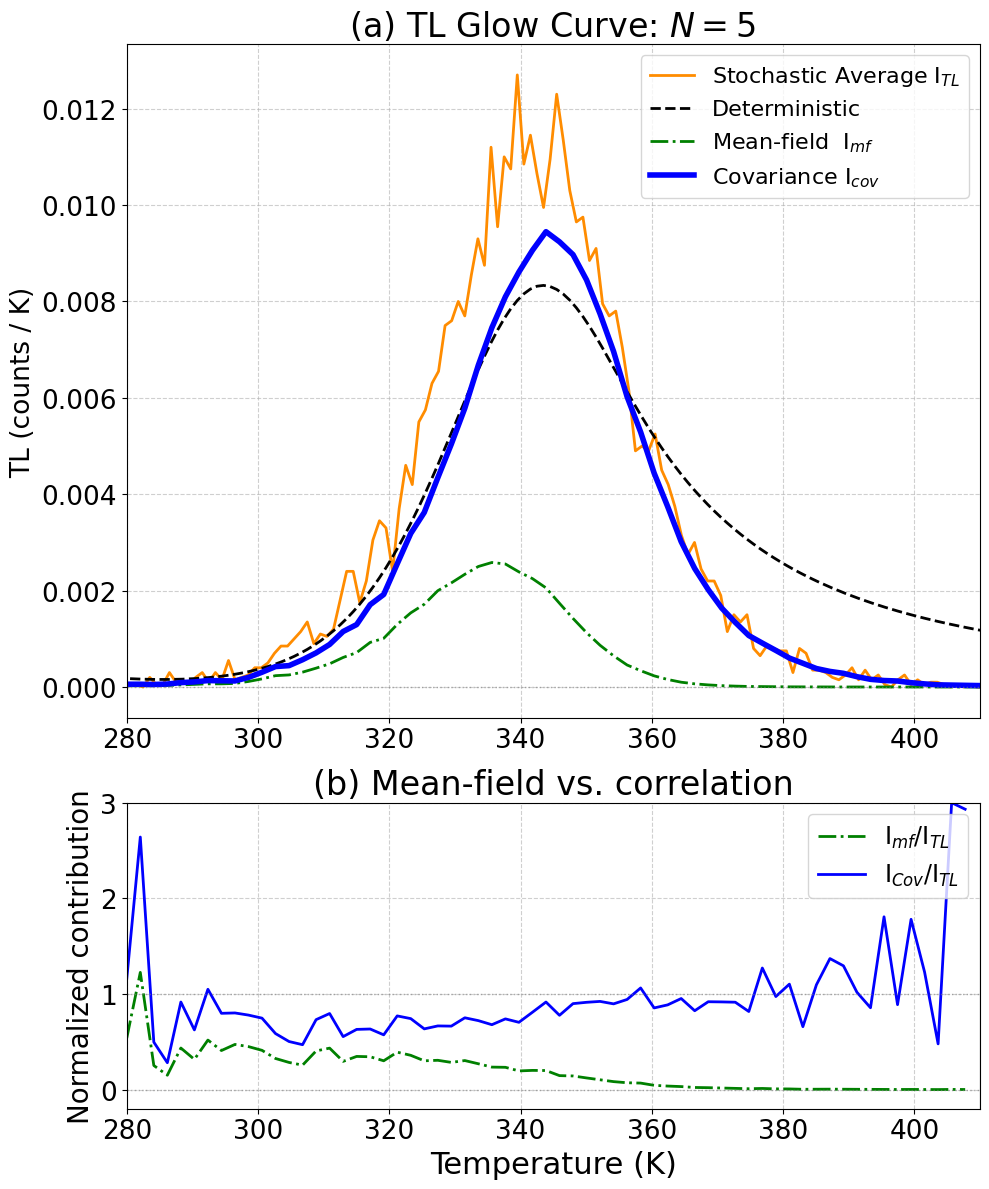

Saved -> otor_panel_data.npz
Arrays saved: ['A_m', 'Am_cov', 'N_val', 'T0', 'beta', 'bin_centers', 'det_intensity_bins', 'heat_m_arr', 'heat_nc_arr', 'heat_temps_cov', 'mean_field_TL', 'mean_heat_m', 'mean_heat_nc', 'mean_intensity', 'rho1', 'rho2', 't_heat_max', 'tl_threshold', 'valid_mask', 'xlim_bot', 'xlim_top']


In [5]:
# -*- coding: utf-8 -*-
"""
OTOR Model Simulation for N = 2.
Panel 1: TL glow curves + mean-field + A_m*Cov + scaled <nc> + scaled <m>
Panel 2: normalized contributions rho1, rho2 (rho1 + rho2 = 1)
"""

import matplotlib.pyplot as plt
from numba import njit
import numpy as np
from scipy.integrate import solve_ivp
import time
start_time = time.time()

# --- Fixed Physical Constants ---
Nref = 5
E = 0.87
s = 1e12
k_B = 8.617333e-5

# --- Fixed Protocol Parameters ---
T0 = 280.0
beta = 1.0
t_irr = 5
t_relax = 80.0
t_heat_max = 410.0
dt_micro = 0.001


@njit
def simulate_single_trajectory(
    N, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
    t_irr, t_relax, t_heat_max, dt_micro,
):
  irr_times = np.linspace(0.0, t_irr, 50)
  irr_states = np.zeros((len(irr_times), 4))

  rel_times = np.linspace(0.0, t_relax, 100)
  rel_states = np.zeros((len(rel_times), 4))

  heat_temps = np.linspace(T0, T0 + beta * t_heat_max, 200)
  heat_states = np.zeros((len(heat_temps), 4))
  emission_temps_buf = np.empty(N * 4 + 200, dtype=np.float64)
  emission_count = 0

  t = 0.0
  n = 0.0
  nc = 0.0
  m = 0.0
  nv = 0.0

  p_room = s * np.exp(-E / (k_B * T0))

  # --- Phase 1: Irradiation ---
  irr_idx = 0
  while t < t_irr:
    while irr_idx < len(irr_times) and t >= irr_times[irr_idx]:
      irr_states[irr_idx, 0] = n
      irr_states[irr_idx, 1] = nc
      irr_states[irr_idx, 2] = m
      irr_states[irr_idx, 3] = nv
      irr_idx += 1

    t_end = min(t + dt_micro, t_irr)
    while t < t_end:
      a1 = G
      a2 = n * p_room
      a3 = A_n * max(0.0, float(N - n)) * nc
      a4 = A_m * max(0.0, float(m)) * nc
      a5 = B_m * max(0.0, float(N - m)) * nv
      a0 = a1 + a2 + a3 + a4 + a5
      if a0 <= 0:
        break
      tau = -np.log(np.random.uniform(0.0, 1.0)) / a0
      if t + tau > t_end:
        break
      t += tau
      u = np.random.uniform(0.0, 1.0) * a0
      if u < a1:
        nc += 1; nv += 1
      elif u < a1 + a2:
        n -= 1; nc += 1
      elif u < a1 + a2 + a3:
        n += 1; nc -= 1
      elif u < a1 + a2 + a3 + a4:
        nc -= 1; m -= 1
      else:
        nv -= 1; m += 1
    t = t_end

  while irr_idx < len(irr_times):
    irr_states[irr_idx, 0] = n
    irr_states[irr_idx, 1] = nc
    irr_states[irr_idx, 2] = m
    irr_states[irr_idx, 3] = nv
    irr_idx += 1

  # --- Phase 2: Relaxation ---
  t_rel = 0.0
  rel_idx = 0
  while t_rel < t_relax:
    while rel_idx < len(rel_times) and t_rel >= rel_times[rel_idx]:
      rel_states[rel_idx, 0] = n
      rel_states[rel_idx, 1] = nc
      rel_states[rel_idx, 2] = m
      rel_states[rel_idx, 3] = nv
      rel_idx += 1

    t_end = min(t_rel + dt_micro, t_relax)
    while t_rel < t_end:
      a2 = n * p_room
      a3 = A_n * max(0.0, float(N - n)) * nc
      a4 = A_m * max(0.0, float(m)) * nc
      a5 = B_m * max(0.0, float(N - m)) * nv
      a0 = a2 + a3 + a4 + a5
      if a0 <= 0:
        break
      tau = -np.log(np.random.uniform(0.0, 1.0)) / a0
      if t_rel + tau > t_end:
        break
      t_rel += tau
      u = np.random.uniform(0.0, 1.0) * a0
      if u < a2:
        n -= 1; nc += 1
      elif u < a2 + a3:
        n += 1; nc -= 1
      elif u < a2 + a3 + a4:
        nc -= 1; m -= 1
      else:
        nv -= 1; m += 1
    t_rel = t_end

  while rel_idx < len(rel_times):
    rel_states[rel_idx, 0] = n
    rel_states[rel_idx, 1] = nc
    rel_states[rel_idx, 2] = m
    rel_states[rel_idx, 3] = nv
    rel_idx += 1

  # --- Phase 3: Heating / TL Readout ---
  t_heat = 0.0
  heat_idx = 0
  while t_heat < t_heat_max and (n > 0 or nc > 0 or nv > 0 or m > 0):
    T_current = T0 + beta * t_heat
    while heat_idx < len(heat_temps) and T_current >= heat_temps[heat_idx]:
      heat_states[heat_idx, 0] = n
      heat_states[heat_idx, 1] = nc
      heat_states[heat_idx, 2] = m
      heat_states[heat_idx, 3] = nv
      heat_idx += 1

    t_end = min(t_heat + dt_micro, t_heat_max)
    p_val = s * np.exp(-E / (k_B * T_current))

    while t_heat < t_end:
      a1 = n * p_val
      a2 = A_n * max(0.0, float(N - n)) * nc
      a3 = A_m * max(0.0, float(m)) * nc
      a4 = B_m * max(0.0, float(N - m)) * nv
      a0 = a1 + a2 + a3 + a4
      if a0 <= 0:
        break
      tau = -np.log(np.random.uniform(0.0, 1.0)) / a0
      if t_heat + tau > t_end:
        break
      t_heat += tau
      T_current = T0 + beta * t_heat
      u = np.random.uniform(0.0, 1.0) * a0
      if u < a1:
        n -= 1; nc += 1
      elif u < a1 + a2:
        n += 1; nc -= 1
      elif u < a1 + a2 + a3:
        nc -= 1; m -= 1
        if emission_count < len(emission_temps_buf):
          emission_temps_buf[emission_count] = T_current
          emission_count += 1
      else:
        nv -= 1; m += 1
    t_heat = t_end

  while heat_idx < len(heat_temps):
    heat_states[heat_idx, 0] = n
    heat_states[heat_idx, 1] = nc
    heat_states[heat_idx, 2] = m
    heat_states[heat_idx, 3] = nv
    heat_idx += 1

  return irr_states, rel_states, heat_states, emission_temps_buf[:emission_count]


def run_simulation(N_val, seed=42):
  base_runs = 20000
  num_runs = int(round(base_runs * Nref / N_val))
  num_runs = max(num_runs, 100)

  A_n = 0.005 * Nref / N_val
  A_m = 0.1   * Nref / N_val
  B_m = 0.1   * Nref / N_val
  G   = 0.5   * N_val / Nref

  np.random.seed(42)

  bin_width = 1.0
  bins = np.arange(T0, T0 + beta * t_heat_max + bin_width, bin_width)
  bin_centers = (bins[:-1] + bins[1:]) / 2.0

  _ = simulate_single_trajectory(
      N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
      t_irr, t_relax, t_heat_max, dt_micro,
  )

  print(f"  N={N_val}: using num_runs={num_runs}")

  all_intensities, n_end_rel_list, nc_end_rel_list, m_end_rel_list = [], [], [], []
  m_end_irr_list = []                     # NEW: m at end of irradiation per trajectory
  heat_nc_list, heat_n_list, heat_m_list = [], [], []
  print_interval = max(num_runs // 4, 1)

  for i in range(num_runs):
    irr_st, rel_st, heat_st, event_temps = simulate_single_trajectory(
        N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
        t_irr, t_relax, t_heat_max, dt_micro,
    )
    hist, _ = np.histogram(event_temps, bins=bins)
    all_intensities.append(hist / bin_width)
    n_end_rel_list.append(rel_st[-1, 0])
    nc_end_rel_list.append(rel_st[-1, 1])
    m_end_rel_list.append(rel_st[-1, 2])
    m_end_irr_list.append(irr_st[-1, 2])   # NEW: m at end of irradiation
    heat_nc_list.append(heat_st[:, 1])
    heat_n_list.append(heat_st[:, 0])
    heat_m_list.append(heat_st[:, 2])
    if (i + 1) % print_interval == 0 or (i + 1) == num_runs:
      elapsed = time.time() - start_time
      print(f"  N={N_val}: {i + 1}/{num_runs} runs. Elapsed: {elapsed:.2f} s")

  mean_intensity  = np.mean(all_intensities, axis=0)
  mean_n_end_rel  = float(np.mean(n_end_rel_list))
  mean_nc_end_rel = float(np.mean(nc_end_rel_list))
  mean_m_end_rel  = float(np.mean(m_end_rel_list))
  mean_m_end_irr  = float(np.mean(m_end_irr_list))   # NEW
  mean_heat_nc    = np.mean(heat_nc_list, axis=0)
  mean_heat_n     = np.mean(heat_n_list, axis=0)
  mean_heat_m     = np.mean(heat_m_list, axis=0)

  p_room_det = s * np.exp(-E / (k_B * T0))

  def ode_irr(t, y):
    n, nc, m, nv = y
    dn = -n * p_room_det + A_n * max(0.0, float(N_val - n)) * nc
    dnc = (G - n * p_room_det
           - A_n * max(0.0, float(N_val - n)) * nc
           - A_m * max(0.0, float(m)) * nc)
    dm = -A_m * max(0.0, float(m)) * nc + B_m * max(0.0, float(N_val - m)) * nv
    dnv = G - B_m * max(0.0, float(N_val - m)) * nv
    return [dn, dnc, dm, dnv]

  sol_irr = solve_ivp(ode_irr, [0, t_irr], [0.0, 0.0, 0.0, 0.0], method='LSODA')
  y0_relax = sol_irr.y[:, -1]
  det_m_end_irr = float(sol_irr.y[2, -1])   # NEW: det m at end of irradiation

  def ode_relax(t, y):
    n, nc, m, nv = y
    dn = -n * p_room_det + A_n * max(0.0, float(N_val - n)) * nc
    dnc = (n * p_room_det
           - A_n * max(0.0, float(N_val - n)) * nc
           - A_m * max(0.0, float(m)) * nc)
    dm = -A_m * max(0.0, float(m)) * nc + B_m * max(0.0, float(N_val - m)) * nv
    dnv = -B_m * max(0.0, float(N_val - m)) * nv
    return [dn, dnc, dm, dnv]

  sol_relax = solve_ivp(ode_relax, [0, t_relax], y0_relax, method='LSODA')
  det_n_end_rel  = float(sol_relax.y[0, -1])
  det_nc_end_rel = float(sol_relax.y[1, -1])
  det_m_end_rel  = float(sol_relax.y[2, -1])
  y0_heat = sol_relax.y[:, -1]

  def ode_heat(t, y):
    n, nc, m, nv = y
    T = T0 + beta * t
    p = s * np.exp(-E / (k_B * T))
    dn = -n * p + A_n * max(0.0, float(N_val - n)) * nc
    dnc = (n * p
           - A_n * max(0.0, float(N_val - n)) * nc
           - A_m * max(0.0, float(m)) * nc)
    dm = -A_m * max(0.0, float(m)) * nc + B_m * max(0.0, float(N_val - m)) * nv
    dnv = -B_m * max(0.0, float(N_val - m)) * nv
    return [dn, dnc, dm, dnv]

  t_bin_eval = np.clip((bin_centers - T0) / beta, 0, t_heat_max)
  sol_heat_bins = solve_ivp(
      ode_heat, [0, t_heat_max], y0_heat, t_eval=t_bin_eval, method='LSODA'
  )

  det_intensity_bins = np.array([
      A_m * max(0.0, float(m_val)) * max(0.0, float(nc_val))
      for n_val, nc_val, m_val, nv_val in sol_heat_bins.y.T
  ])

  heat_temps = np.linspace(T0, T0 + beta * t_heat_max, 200)
  t_heat_eval = np.clip((heat_temps - T0) / beta, 0, t_heat_max)
  sol_heat_full = solve_ivp(
      ode_heat, [0, t_heat_max], y0_heat, t_eval=t_heat_eval, method='LSODA'
  )
  det_heat_nc = sol_heat_full.y[1]
  det_heat_n  = sol_heat_full.y[0]
  det_heat_m  = sol_heat_full.y[2]

  stoch_area = np.sum(mean_intensity * bin_width)
  det_area = np.sum(det_intensity_bins * bin_width)
  diff_pct = 100 * (stoch_area - det_area) / det_area

  print(f"  N={N_val}: Stoch Area={stoch_area:.4f}, "
        f"Det Area={det_area:.4f}, Rel Diff={diff_pct:.2f}%")
  print(f"  N={N_val}: Mean n  at end of relaxation = {mean_n_end_rel:.4f}, "
        f"Det n  = {det_n_end_rel:.4f}")
  print(f"  N={N_val}: Mean nc at end of relaxation = {mean_nc_end_rel:.4f}, "
        f"Det nc = {det_nc_end_rel:.4f}")
  print(f"  N={N_val}: Mean m  at end of relaxation = {mean_m_end_rel:.4f}, "
        f"Det m  = {det_m_end_rel:.4f}")

  # --- NEW: m0 at end of irradiation and relaxation vs area ---
  print("\n  --- m0 (filled recombination centers) vs glow-curve area ---")
  print(f"  {'Phase':<22} {'stoch m0':>10} {'det m0':>10} "
        f"{'stoch/det':>10} {'diff %':>10}")
  print(f"  {'end of irradiation':<22} {mean_m_end_irr:>10.4f} "
        f"{det_m_end_irr:>10.4f} "
        f"{mean_m_end_irr/det_m_end_irr if det_m_end_irr>0 else float('nan'):>10.4f} "
        f"{100*(mean_m_end_irr-det_m_end_irr)/det_m_end_irr if det_m_end_irr>0 else float('nan'):>+10.2f}%")
  print(f"  {'end of relaxation':<22} {mean_m_end_rel:>10.4f} "
        f"{det_m_end_rel:>10.4f} "
        f"{mean_m_end_rel/det_m_end_rel if det_m_end_rel>0 else float('nan'):>10.4f} "
        f"{100*(mean_m_end_rel-det_m_end_rel)/det_m_end_rel if det_m_end_rel>0 else float('nan'):>+10.2f}%")
  print(f"  {'glow-curve area':<22} {stoch_area:>10.4f} "
        f"{det_area:>10.4f} "
        f"{stoch_area/det_area if det_area>0 else float('nan'):>10.4f} "
        f"{diff_pct:>+10.2f}%")
  area_ratio = stoch_area / det_area if det_area > 0 else float('nan')
  m0_irr_ratio = mean_m_end_irr / det_m_end_irr if det_m_end_irr > 0 else float('nan')
  m0_rel_ratio = mean_m_end_rel / det_m_end_rel if det_m_end_rel > 0 else float('nan')
  print(f"\n  Check A ≈ m0 at end of relaxation:")
  print(f"    area ratio        = {area_ratio:.4f}")
  print(f"    m0(stoch)/m0(det) = {m0_rel_ratio:.4f}")
  print(f"    |area - m0_ratio| = {abs(area_ratio - m0_rel_ratio):.4f} "
        f"({100*abs(area_ratio - m0_rel_ratio)/m0_rel_ratio:.2f}% of m0 ratio)")
  print(f"  Check m0 change during relaxation (stoch / det):")
  print(f"    stoch: {mean_m_end_irr:.4f} -> {mean_m_end_rel:.4f} "
        f"({100*(mean_m_end_rel-mean_m_end_irr)/mean_m_end_irr if mean_m_end_irr>0 else float('nan'):+.2f}%)")
  print(f"    det  : {det_m_end_irr:.4f} -> {det_m_end_rel:.4f} "
        f"({100*(det_m_end_rel-det_m_end_irr)/det_m_end_irr if det_m_end_irr>0 else float('nan'):+.2f}%)")
  print(f"  m0 ratio created during irradiation = {m0_irr_ratio:.4f}, "
        f"after relaxation = {m0_rel_ratio:.4f}")
  print(f"  => filling bias is {'mostly set during irradiation' if abs(m0_irr_ratio - m0_rel_ratio) < 0.05 else 'changed by relaxation'}")
  print()

  # --- Diagnostic: how much does <m> change across heating? ---
  m_start = float(mean_heat_m[0])
  m_end   = float(mean_heat_m[-1])
  m_min   = float(np.min(mean_heat_m))
  frac_drop_total = (m_start - m_end) / m_start if m_start > 0 else float('nan')
  frac_drop_to_min = (m_start - m_min) / m_start if m_start > 0 else float('nan')
  print(f"  N={N_val}: <m> start={m_start:.4f}, end={m_end:.4f}, "
        f"min={m_min:.4f}")
  print(f"  N={N_val}: <m> fractional drop start->end = "
        f"{frac_drop_total*100:.2f}%  (start->min = {frac_drop_to_min*100:.2f}%)")

  heat_nc_arr = np.array(heat_nc_list)
  heat_m_arr  = np.array(heat_m_list)

  return (bin_centers, mean_intensity, det_intensity_bins, diff_pct,
          mean_n_end_rel,  det_n_end_rel,
          mean_nc_end_rel, det_nc_end_rel,
          mean_m_end_rel,  det_m_end_rel,
          mean_heat_nc,    det_heat_nc,
          mean_heat_n,     det_heat_n,
          mean_heat_m,     det_heat_m,
          heat_nc_arr, heat_m_arr, A_m)


# ============================================================================
# Run for N = 5
# ============================================================================
N_val = 5

print('\n' + '=' * 60)
print(f'RUNNING SIMULATION FOR N = {N_val}')
print('=' * 60)

result = run_simulation(N_val, seed=42)

print('\n' + '=' * 60)
print('SUMMARY OF GLOW CURVE AREA COMPARISON')
print('=' * 60)
print(f'  N = {N_val}: Relative Difference = {result[3]:.2f}%')
print('=' * 60)


# ============================================================================
# Two-panel figure
# ============================================================================
heat_temps_cov = np.linspace(T0, T0 + beta * t_heat_max, 200)

(bin_centers, mean_intensity, det_intensity_bins, diff_pct,
 mean_n_end_rel,  det_n_end_rel,
 mean_nc_end_rel, det_nc_end_rel,
 mean_m_end_rel,  det_m_end_rel,
 mean_heat_nc,    det_heat_nc,
 mean_heat_n,     det_heat_n,
 mean_heat_m,     det_heat_m,
 heat_nc_arr, heat_m_arr, A_m) = result





fig, (ax, ax2) = plt.subplots(
    2, 1, figsize=(10, 12), sharex=False,
    gridspec_kw={'height_ratios': [2.2, 1.0]},
)

# ----------------------------------------------------------------------------
# Panel 1
# ----------------------------------------------------------------------------
ax.plot(bin_centers, mean_intensity, color='darkorange', lw=2,
        label='Stochastic Average I$_{TL}$')
ax.plot(bin_centers, det_intensity_bins, color='black', linestyle='--', lw=2,
        label='Deterministic')

mean_field_TL = A_m * mean_heat_nc * mean_heat_m
ax.plot(heat_temps_cov, mean_field_TL, color='green', linestyle='-.', lw=2,
        label=r'Mean-field  I$_{mf}$')

cov_nc_m = (np.mean(heat_nc_arr * heat_m_arr, axis=0)
            - np.mean(heat_nc_arr, axis=0) * np.mean(heat_m_arr, axis=0))
Am_cov = A_m * cov_nc_m
ax.plot(heat_temps_cov, Am_cov, color='blue', lw=4.0, linestyle='-',
        label=r'Covariance I$_{cov}$')
ax.axhline(0, color='gray', linestyle='dotted', lw=1.0, alpha=0.6)

ax.set_ylabel('TL (counts / K)', fontsize=19)
ax.set_title(f'(a) TL Glow Curve: $N={N_val}$ ', fontsize=24)
ax.grid(True, linestyle='--', alpha=0.6)
ax.tick_params(axis='both', labelsize=19)
ax.legend(frameon=True, fontsize=16, loc='upper right')
ax.set_xlim(280, 410)                        # extended top panel

# ----------------------------------------------------------------------------
# Panel 2: rho1 and rho2  (extended to 420 K)
# ----------------------------------------------------------------------------
TL_heat = np.interp(heat_temps_cov, bin_centers, mean_intensity)
glow_peak = np.max(mean_intensity)
# Lowered threshold so rho is defined well into the glow-curve tail
tl_threshold = 2e-4 * glow_peak
valid = TL_heat > tl_threshold

rho1 = np.full_like(TL_heat, np.nan)
rho2 = np.full_like(TL_heat, np.nan)
with np.errstate(invalid='ignore', divide='ignore'):
    rho1[valid] = mean_field_TL[valid] / TL_heat[valid]
    rho2[valid] = Am_cov[valid] / TL_heat[valid]

# Wider clip so tail values are not artificially flattened
rho1 = np.clip(rho1, -1.0, 3.0)
rho2 = np.clip(rho2, -1.0, 3.0)

ax2.plot(heat_temps_cov, rho1, color='green', linestyle='-.', lw=2,
         label=r'I$_{mf}$/I$_{TL}$')
ax2.plot(heat_temps_cov, rho2, color='blue', lw=2,
         label=r'I$_{Cov}$/I$_{TL}$')
ax2.axhline(0.0, color='gray', linestyle=':', lw=1.0, alpha=0.6)
ax2.axhline(1.0, color='gray', linestyle=':', lw=1.0, alpha=0.6)
if np.any(~valid):
    ax2.axvspan(heat_temps_cov[~valid].min(), heat_temps_cov[-1],
                color='lightgray', alpha=0.25, lw=0)

ax2.set_xlabel('Temperature (K)', fontsize=22)
ax2.set_ylabel(r'Normalized contribution', fontsize=20)
ax2.set_title(r'(b) Mean-field vs. correlation', fontsize=24)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_xlim(280, 410)                       # extended bottom panel
ax2.set_ylim(-0.2, 3.0)                      # matches wider clip
ax2.tick_params(axis='both', labelsize=19)
ax2.legend(frameon=True, fontsize=17, loc='upper right')

plt.tight_layout()
plt.show()


# ============================================================================
# SAVE UNCOMPRESSED DATA REQUIRED TO REPRODUCE THE 2x1 FIGURE
# ============================================================================
save_dict = {
    # scalars
    'N_val': np.array(N_val),
    'A_m':   np.array(A_m),
    'T0':    np.array(T0),
    'beta':  np.array(beta),
    't_heat_max': np.array(t_heat_max),

    # top panel
    'bin_centers':          bin_centers,
    'mean_intensity':       mean_intensity,
    'det_intensity_bins':   det_intensity_bins,
    'heat_temps_cov':       heat_temps_cov,
    'mean_heat_nc':         mean_heat_nc,
    'mean_heat_m':          mean_heat_m,
    'heat_nc_arr':          heat_nc_arr,
    'heat_m_arr':           heat_m_arr,

    # panel 2 (with new threshold + clip already applied)
    'mean_field_TL':        mean_field_TL,
    'Am_cov':               Am_cov,
    'rho1':                 rho1,
    'rho2':                 rho2,
    'valid_mask':           valid,
    'tl_threshold':         np.array(tl_threshold),
    'xlim_top':             np.array([280., 420.]),
    'xlim_bot':             np.array([280., 420.]),
}

# np.savez('otor_panel_data.npz', **save_dict)
print("Saved -> otor_panel_data.npz")
print("Arrays saved:", sorted(save_dict.keys()))


RUNNING SIMULATIONS FOR N = 2, 3, 5, 10, 20, 100

--- N = 2 ---
  N=2: using num_runs=50000
  N=2: 12500/50000 runs. Elapsed: 2.49 s
  N=2: 25000/50000 runs. Elapsed: 2.98 s
  N=2: 37500/50000 runs. Elapsed: 3.47 s
  N=2: 50000/50000 runs. Elapsed: 3.97 s
  N=2: Stoch Area=0.1169, Det Area=0.1958, Rel Diff=-40.29%
  N=2: Mean n  at end of relaxation = 0.1168, Det n  = 0.2051
  N=2: Mean nc at end of relaxation = 0.0001, Det nc = 0.0014
  N=2: Mean m  at end of relaxation = 0.1169, Det m  = 0.2065

--- N = 3 ---
  N=3: using num_runs=33333
  N=3: 8333/33333 runs. Elapsed: 4.98 s
  N=3: 16666/33333 runs. Elapsed: 5.45 s
  N=3: 24999/33333 runs. Elapsed: 6.04 s
  N=3: 33332/33333 runs. Elapsed: 6.59 s
  N=3: 33333/33333 runs. Elapsed: 6.59 s
  N=3: Stoch Area=0.2074, Det Area=0.2937, Rel Diff=-29.39%
  N=3: Mean n  at end of relaxation = 0.2071, Det n  = 0.3077
  N=3: Mean nc at end of relaxation = 0.0003, Det nc = 0.0021
  N=3: Mean m  at end of relaxation = 0.2074, Det m  = 0.3098

---

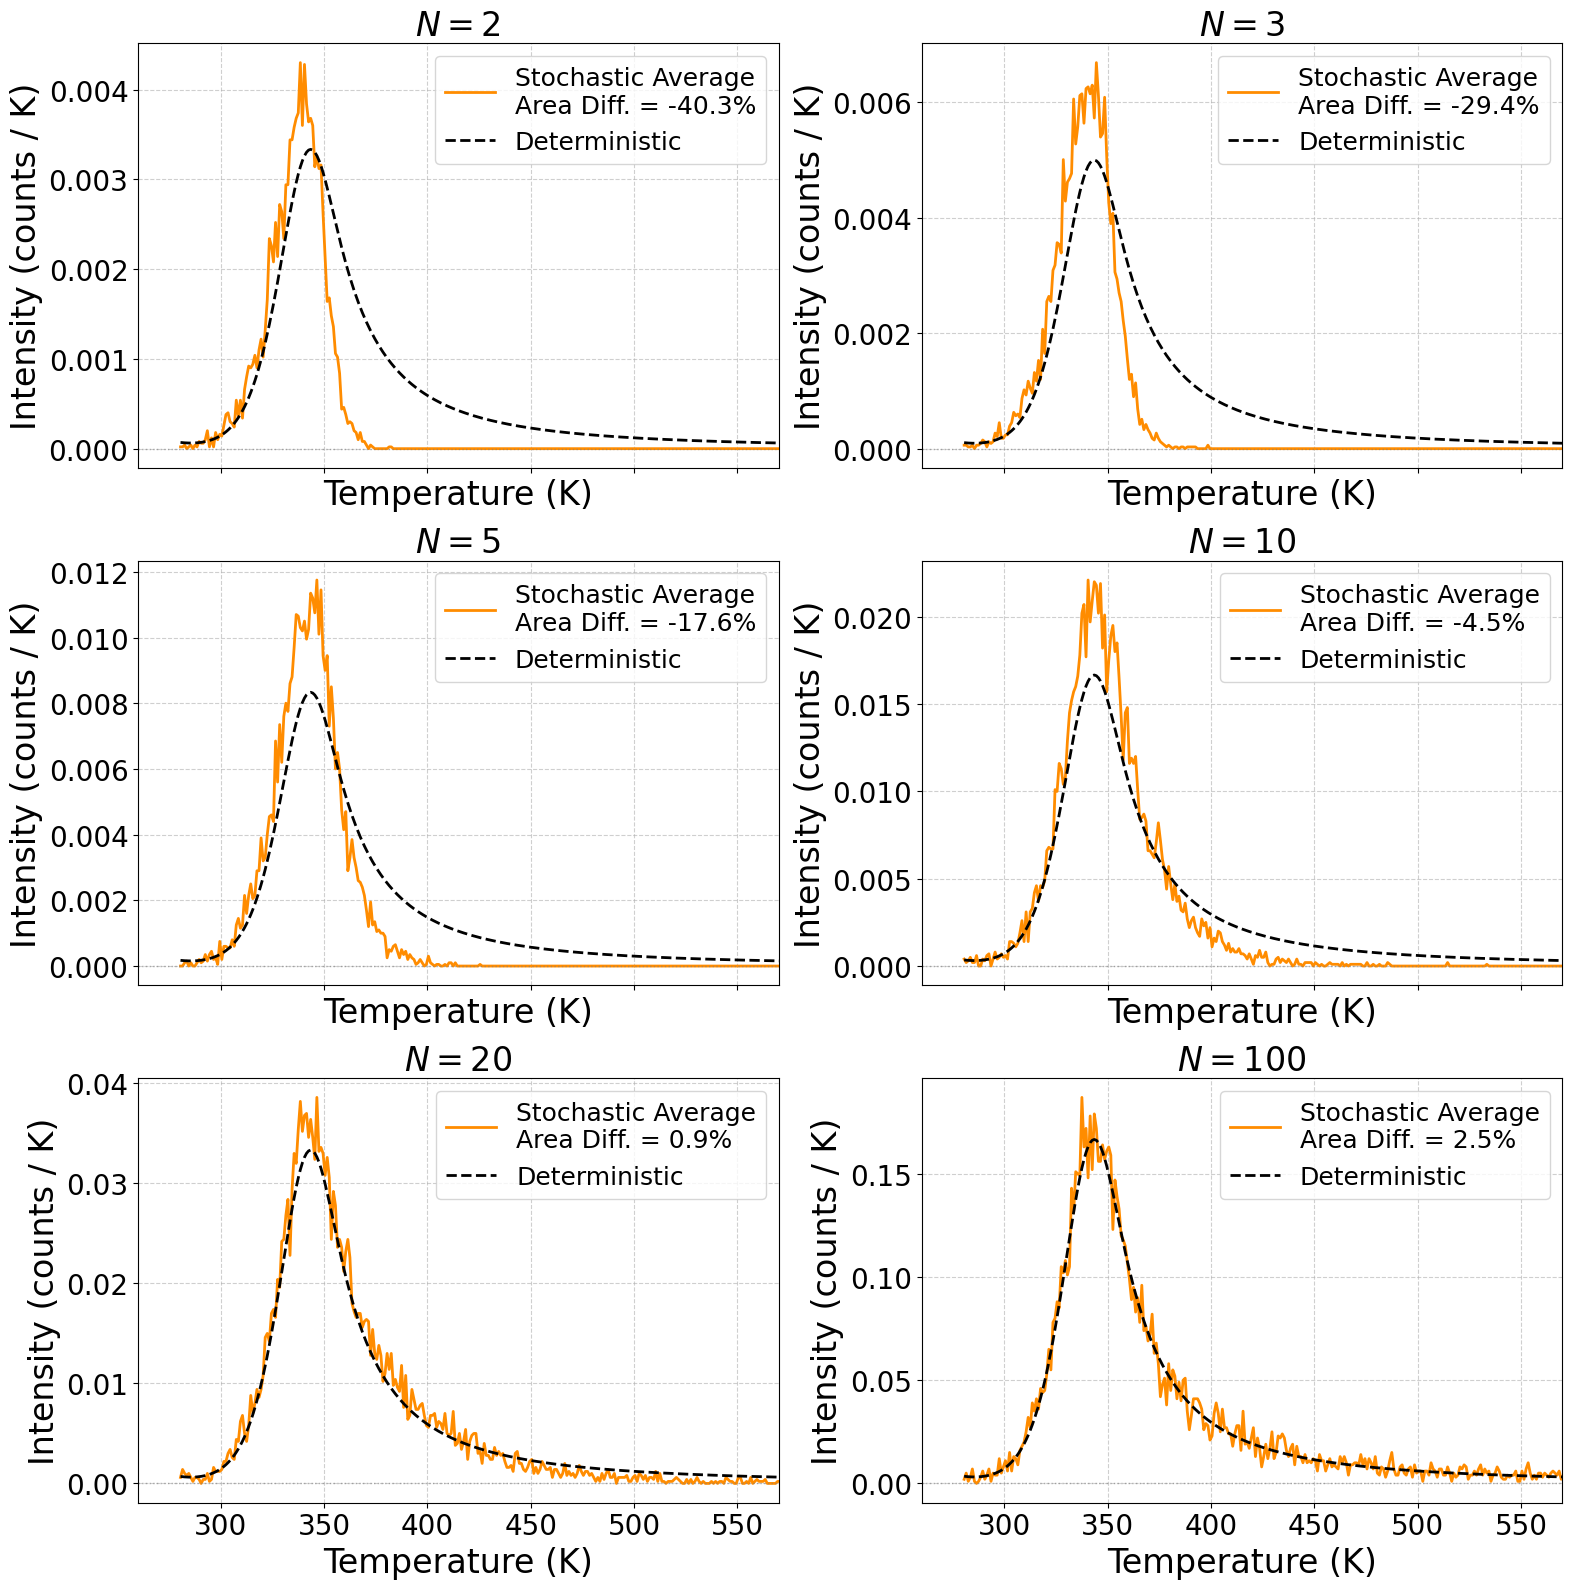

Saved -> otor_multin_data.npz
Arrays saved: 118 entries, N_values = [2, 3, 5, 10, 20, 100]


In [6]:
# -*- coding: utf-8 -*-
"""
OTOR Model Simulation with Valence Band Hole Dynamics (nv), Hole Capture (Bm),
and Total Recombination Center Capacity M = N.

Generates a 3x2 panel of TL glow curves for N = 2, 3, 5, 10, 20, 100.

*** Direct Gillespie (no dt_micro) ***
  Phase 1, 2 : constant propensities -> tau = -ln(u)/a0 (exact)
  Phase 3    : time-dependent a0(t)   -> tau from inverting
               Lambda(tau) = ∫ a0 dt = -ln(u) via Simpson + bisection
Fill-order fix: stamp [t, t_next) with pre-jump state before jumping.

The number of stochastic runs scales inversely with N:
    num_runs(N) = round(base_runs * Nref / N)
"""

import matplotlib.pyplot as plt
from numba import njit
import numpy as np
from scipy.integrate import solve_ivp
import time
start_time = time.time()

# --- Fixed Physical Constants ---
Nref = 5
E    = 0.87
s    = 1e12
k_B  = 8.617333e-5

# --- Fixed Protocol Parameters ---
T0         = 280.0
beta       = 1.0
t_irr      = 5.0
t_relax    = 80.0
t_heat_max = 410.0


# ============================================================================
# Time-dependent hazard helpers (Numba) — Phase 3
# ============================================================================
@njit(cache=True)
def _hazard_increment(t_start, tau, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub):
    """∫_0^tau a0(t_start+s) ds  via composite Simpson."""
    if tau <= 0.0:
        return 0.0
    a_const = (A_n * max(0.0, N - n) * nc
               + A_m * max(0.0, m)     * nc
               + B_m * max(0.0, N - m) * nv)
    if n_sub % 2 == 1:
        n_sub += 1
    h = tau / n_sub
    total = 0.0
    for i in range(n_sub + 1):
        tt = t_start + i * h
        T  = T0 + beta * tt
        p  = s * np.exp(-E / (k_B * T))
        val = n * p + a_const
        if i == 0 or i == n_sub:
            w = 1.0
        elif i % 2 == 1:
            w = 4.0
        else:
            w = 2.0
        total += w * val
    return total * h / 3.0


@njit(cache=True)
def _draw_heating_tau(t_start, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                      u, t_heat_max, tol, n_sub):
    """Find tau >= 0 s.t. ∫_0^tau a0(t_start+s) ds = -ln(u)."""
    target = -np.log(u)
    t_remaining = t_heat_max - t_start
    if t_remaining <= 0.0:
        return 0.0
    full = _hazard_increment(t_start, t_remaining, n, nc, m, nv,
                             A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
    if full < target:
        return t_remaining + 1.0
    lo = 0.0
    hi = t_remaining
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        hmid = _hazard_increment(t_start, mid, n, nc, m, nv,
                                 A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
        if hmid < target:
            lo = mid
        else:
            hi = mid
        if (hi - lo) < tol:
            break
    return 0.5 * (lo + hi)


@njit(cache=True)
def _select_channel(u, a1, a2, a3, a4, a5, a0):
    uu = u * a0
    if uu < a1:
        return 1
    uu -= a1
    if uu < a2:
        return 2
    uu -= a2
    if uu < a3:
        return 3
    uu -= a3
    if uu < a4:
        return 4
    return 5


# ============================================================================
# Direct-Gillespie simulator (no dt_micro), fill-order fix
# ============================================================================
@njit(cache=True)
def simulate_single_trajectory(
    N, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
    t_irr, t_relax, t_heat_max,
):
    irr_times   = np.linspace(0.0, t_irr, 50)
    irr_states  = np.zeros((len(irr_times), 4))

    rel_times   = np.linspace(0.0, t_relax, 100)
    rel_states  = np.zeros((len(rel_times), 4))

    heat_temps  = np.linspace(T0, T0 + beta * t_heat_max, 200)
    heat_states = np.zeros((len(heat_temps), 4))

    emission_temps_buf = np.empty(N * 4 + 200, dtype=np.float64)
    emission_count = 0

    n = 0.0; nc = 0.0; m = 0.0; nv = 0.0
    p_room = s * np.exp(-E / (k_B * T0))

    # ---------------- PHASE 1: Irradiation ----------------
    t   = 0.0
    idx = 0
    while t < t_irr:
        a1 = G
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t + tau

        while idx < len(irr_times) and irr_times[idx] < t_next:
            irr_states[idx, 0] = n
            irr_states[idx, 1] = nc
            irr_states[idx, 2] = m
            irr_states[idx, 3] = nv
            idx += 1

        if t_next > t_irr:
            break

        t = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 1: nc += 1; nv += 1
        elif ch == 2: n  -= 1; nc += 1
        elif ch == 3: n  += 1; nc -= 1
        elif ch == 4: nc -= 1; m  -= 1
        else:         nv -= 1; m  += 1

    while idx < len(irr_times):
        irr_states[idx, 0] = n; irr_states[idx, 1] = nc
        irr_states[idx, 2] = m; irr_states[idx, 3] = nv
        idx += 1

    # ---------------- PHASE 2: Relaxation ----------------
    t_rel = 0.0
    idx   = 0
    while t_rel < t_relax:
        a1 = 0.0
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t_rel + tau

        while idx < len(rel_times) and rel_times[idx] < t_next:
            rel_states[idx, 0] = n; rel_states[idx, 1] = nc
            rel_states[idx, 2] = m; rel_states[idx, 3] = nv
            idx += 1

        if t_next > t_relax:
            break

        t_rel = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 2: n  -= 1; nc += 1
        elif ch == 3: n  += 1; nc -= 1
        elif ch == 4: nc -= 1; m  -= 1
        else:         nv -= 1; m  += 1

    while idx < len(rel_times):
        rel_states[idx, 0] = n; rel_states[idx, 1] = nc
        rel_states[idx, 2] = m; rel_states[idx, 3] = nv
        idx += 1

    # ---------------- PHASE 3: Heating ----------------
    t_heat = 0.0
    idx    = 0
    tol    = 1e-9
    n_sub  = 16

    while t_heat < t_heat_max and (n > 0 or nc > 0 or nv > 0 or m > 0):
        T_now = T0 + beta * t_heat
        p_now = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        u   = np.random.uniform(0.0, 1.0)
        tau = _draw_heating_tau(t_heat, n, nc, m, nv,
                                A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                                u, t_heat_max, tol, n_sub)
        if t_heat + tau > t_heat_max or tau > (t_heat_max - t_heat):
            t_next = t_heat_max
        else:
            t_next = t_heat + tau

        T_next = T0 + beta * t_next
        while idx < len(heat_temps) and heat_temps[idx] < T_next:
            heat_states[idx, 0] = n; heat_states[idx, 1] = nc
            heat_states[idx, 2] = m; heat_states[idx, 3] = nv
            idx += 1

        if t_next >= t_heat_max:
            t_heat = t_heat_max
            break

        t_heat = t_next
        T_now  = T0 + beta * t_heat
        p_now  = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, 0.0, a0)
        if   ch == 1: n  -= 1; nc += 1
        elif ch == 2: n  += 1; nc -= 1
        elif ch == 3:
            nc -= 1; m  -= 1
            if emission_count < len(emission_temps_buf):
                emission_temps_buf[emission_count] = T_now
                emission_count += 1
        else:         nv -= 1; m  += 1

    while idx < len(heat_temps):
        heat_states[idx, 0] = n; heat_states[idx, 1] = nc
        heat_states[idx, 2] = m; heat_states[idx, 3] = nv
        idx += 1

    return (irr_states, rel_states, heat_states,
            emission_temps_buf[:emission_count])


# ============================================================================
# Simulation driver for a given N
# ============================================================================
def run_simulation(N_val, seed=42):
    base_runs = 20000
    num_runs  = max(int(round(base_runs * Nref / N_val)), 100)

    A_n = 0.005 * Nref / N_val
    A_m = 0.1   * Nref / N_val
    B_m = 0.1   * Nref / N_val
    G   = 0.5   * N_val / Nref

    np.random.seed(seed)

    bin_width   = 1.0
    bins        = np.arange(T0, T0 + beta * t_heat_max + bin_width, bin_width)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    # Warm-up JIT
    _ = simulate_single_trajectory(
        N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
        t_irr, t_relax, t_heat_max)

    print(f"  N={N_val}: using num_runs={num_runs}")

    all_intensities  = []
    n_end_rel_list   = []
    nc_end_rel_list  = []
    m_end_rel_list   = []
    heat_nc_list     = []
    heat_n_list      = []
    heat_m_list      = []
    print_interval = max(num_runs // 4, 1)

    for i in range(num_runs):
        _, rel_st, heat_st, event_temps = simulate_single_trajectory(
            N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
            t_irr, t_relax, t_heat_max)

        hist, _ = np.histogram(event_temps, bins=bins)
        all_intensities.append(hist / bin_width)
        n_end_rel_list.append(rel_st[-1, 0])
        nc_end_rel_list.append(rel_st[-1, 1])
        m_end_rel_list.append(rel_st[-1, 2])
        heat_nc_list.append(heat_st[:, 1])
        heat_n_list.append(heat_st[:, 0])
        heat_m_list.append(heat_st[:, 2])

        if (i + 1) % print_interval == 0 or (i + 1) == num_runs:
            elapsed = time.time() - start_time
            print(f"  N={N_val}: {i + 1}/{num_runs} runs. Elapsed: {elapsed:.2f} s")

    mean_intensity  = np.mean(all_intensities, axis=0)
    mean_n_end_rel  = float(np.mean(n_end_rel_list))
    mean_nc_end_rel = float(np.mean(nc_end_rel_list))
    mean_m_end_rel  = float(np.mean(m_end_rel_list))
    mean_heat_nc    = np.mean(heat_nc_list, axis=0)
    mean_heat_n     = np.mean(heat_n_list, axis=0)
    mean_heat_m     = np.mean(heat_m_list, axis=0)

    # ---------------- Deterministic ODE ----------------
    p_room_det = s * np.exp(-E / (k_B * T0))

    def ode_irr(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (G - n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = G - B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    sol_irr   = solve_ivp(ode_irr, [0, t_irr], [0.0]*4, method='LSODA')
    y0_relax  = sol_irr.y[:, -1]

    def ode_relax(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    sol_relax = solve_ivp(ode_relax, [0, t_relax], y0_relax, method='LSODA')
    det_n_end_rel  = float(sol_relax.y[0, -1])
    det_nc_end_rel = float(sol_relax.y[1, -1])
    det_m_end_rel  = float(sol_relax.y[2, -1])
    y0_heat        = sol_relax.y[:, -1]

    def ode_heat(t, y):
        n, nc, m, nv = y
        T = T0 + beta * t
        p = s * np.exp(-E / (k_B * T))
        dn  = -n * p + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    t_bin_eval    = np.clip((bin_centers - T0) / beta, 0, t_heat_max)
    sol_heat_bins = solve_ivp(ode_heat, [0, t_heat_max], y0_heat,
                              t_eval=t_bin_eval, method='LSODA')
    det_intensity_bins = np.array([
        A_m * max(0.0, m_val) * max(0.0, nc_val)
        for n_val, nc_val, m_val, nv_val in sol_heat_bins.y.T
    ])

    heat_temps   = np.linspace(T0, T0 + beta * t_heat_max, 200)
    t_heat_eval  = np.clip((heat_temps - T0) / beta, 0, t_heat_max)
    sol_heat_full = solve_ivp(ode_heat, [0, t_heat_max], y0_heat,
                              t_eval=t_heat_eval, method='LSODA')
    det_heat_nc = sol_heat_full.y[1]
    det_heat_n  = sol_heat_full.y[0]
    det_heat_m  = sol_heat_full.y[2]

    stoch_area = np.sum(mean_intensity * bin_width)
    det_area   = np.sum(det_intensity_bins * bin_width)
    diff_pct   = 100 * (stoch_area - det_area) / det_area

    print(f"  N={N_val}: Stoch Area={stoch_area:.4f}, "
          f"Det Area={det_area:.4f}, Rel Diff={diff_pct:.2f}%")
    print(f"  N={N_val}: Mean n  at end of relaxation = {mean_n_end_rel:.4f}, "
          f"Det n  = {det_n_end_rel:.4f}")
    print(f"  N={N_val}: Mean nc at end of relaxation = {mean_nc_end_rel:.4f}, "
          f"Det nc = {det_nc_end_rel:.4f}")
    print(f"  N={N_val}: Mean m  at end of relaxation = {mean_m_end_rel:.4f}, "
          f"Det m  = {det_m_end_rel:.4f}")

    heat_nc_arr = np.array(heat_nc_list)
    heat_m_arr  = np.array(heat_m_list)

    return (bin_centers, mean_intensity, det_intensity_bins, diff_pct,
            mean_n_end_rel,  det_n_end_rel,
            mean_nc_end_rel, det_nc_end_rel,
            mean_m_end_rel,  det_m_end_rel,
            mean_heat_nc,    det_heat_nc,
            mean_heat_n,     det_heat_n,
            mean_heat_m,     det_heat_m,
            heat_nc_arr, heat_m_arr)


# ============================================================================
# Run the six simulations
# ============================================================================
N_values = [2, 3, 5, 10, 20, 100]
results = {}

print('\n' + '=' * 60)
print('RUNNING SIMULATIONS FOR N = 2, 3, 5, 10, 20, 100')
print('=' * 60)

for N_val in N_values:
    print(f'\n--- N = {N_val} ---')
    results[N_val] = run_simulation(N_val, seed=42)

print('\n' + '=' * 60)
print('SUMMARY OF GLOW CURVE AREA COMPARISON')
print('=' * 60)
for N_val in N_values:
    diff_pct = results[N_val][3]
    print(f'  N = {N_val:>3d}: Relative Difference = {diff_pct:>6.2f}%')
print('=' * 60)


# ============================================================================
# 3x2 panel of TL glow curves for N = 2, 3, 5, 10, 20, 100
# ============================================================================
heat_temps_cov = np.linspace(T0, T0 + beta * t_heat_max, 200)

fig, axes = plt.subplots(3, 2, figsize=(16, 16), sharex=True)

for ax, N_val in zip(axes.ravel(), N_values):
    (bin_centers, mean_intensity, det_intensity_bins, diff_pct,
     mean_n_end_rel,  det_n_end_rel,
     mean_nc_end_rel, det_nc_end_rel,
     mean_m_end_rel,  det_m_end_rel,
     mean_heat_nc,    det_heat_nc,
     mean_heat_n,     det_heat_n,
     mean_heat_m,     det_heat_m,
     heat_nc_arr, heat_m_arr) = results[N_val]

    ax.plot(
        bin_centers, mean_intensity,
        color='darkorange', lw=2,
        label=f'Stochastic Average\nArea Diff. = {diff_pct:.1f}%',
    )
    ax.plot(
        bin_centers, det_intensity_bins,
        color='black', linestyle='--', lw=2,
        label='Deterministic',
    )

    ax.axhline(0, color='gray', linestyle=':', lw=1.0, alpha=0.6)

    ax.set_xlabel('Temperature (K)', fontsize=24)
    ax.set_ylabel('Intensity (counts / K)', fontsize=24)
    ax.set_title(f'$N={N_val}$', fontsize=24)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_xlim(260, 570)
    ax.tick_params(axis='both', labelsize=20)
    ax.legend(frameon=True, fontsize=18, loc='upper right')

plt.tight_layout()
plt.show()


# ============================================================================
# Save data
# ============================================================================
save_dict = {
    'N_values':   np.array(N_values, dtype=np.int64),
    'Nref':       np.array(Nref),
    'E':          np.array(E),
    's':          np.array(s),
    'k_B':        np.array(k_B),
    'T0':         np.array(T0),
    'beta':       np.array(beta),
    't_irr':      np.array(t_irr),
    't_relax':    np.array(t_relax),
    't_heat_max': np.array(t_heat_max),
}

for N_val in N_values:
    (bin_centers, mean_intensity, det_intensity_bins, diff_pct,
     mean_n_end_rel,  det_n_end_rel,
     mean_nc_end_rel, det_nc_end_rel,
     mean_m_end_rel,  det_m_end_rel,
     mean_heat_nc,    det_heat_nc,
     mean_heat_n,     det_heat_n,
     mean_heat_m,     det_heat_m,
     heat_nc_arr, heat_m_arr) = results[N_val]

    p = f'N{N_val}_'
    save_dict[p + 'bin_centers']         = bin_centers
    save_dict[p + 'mean_intensity']      = mean_intensity
    save_dict[p + 'det_intensity_bins']  = det_intensity_bins
    save_dict[p + 'diff_pct']            = np.array(diff_pct)
    save_dict[p + 'mean_n_end_rel']      = np.array(mean_n_end_rel)
    save_dict[p + 'det_n_end_rel']       = np.array(det_n_end_rel)
    save_dict[p + 'mean_nc_end_rel']     = np.array(mean_nc_end_rel)
    save_dict[p + 'det_nc_end_rel']      = np.array(det_nc_end_rel)
    save_dict[p + 'mean_m_end_rel']      = np.array(mean_m_end_rel)
    save_dict[p + 'det_m_end_rel']       = np.array(det_m_end_rel)
    save_dict[p + 'mean_heat_nc']        = mean_heat_nc
    save_dict[p + 'det_heat_nc']         = det_heat_nc
    save_dict[p + 'mean_heat_n']         = mean_heat_n
    save_dict[p + 'det_heat_n']          = det_heat_n
    save_dict[p + 'mean_heat_m']         = mean_heat_m
    save_dict[p + 'det_heat_m']          = det_heat_m
    save_dict[p + 'heat_nc_arr']         = heat_nc_arr
    save_dict[p + 'heat_m_arr']          = heat_m_arr

# np.savez('otor_multin_data.npz', **save_dict)
print("Saved -> otor_multin_data.npz")
print("Arrays saved:", len(save_dict), "entries, N_values =", list(N_values))


RUNNING t_irr SWEEP FOR N = 2
  t_irr_values = [1.0, 5.0, 10.0, 20.0, 50.0, 1000.0]

--- t_irr = 1.0 s ---
  t_irr=1.0: num_runs=20000
  t_irr=1.0: 5000/20000 runs. Elapsed: 4.14 s
  t_irr=1.0: 10000/20000 runs. Elapsed: 4.31 s
  t_irr=1.0: 15000/20000 runs. Elapsed: 4.44 s
  t_irr=1.0: 20000/20000 runs. Elapsed: 4.58 s
  t_irr=1.0: Stoch Area=0.0258, Det Area=0.0802, Rel Diff=-67.75%

--- t_irr = 5.0 s ---
  t_irr=5.0: num_runs=20000
  t_irr=5.0: 5000/20000 runs. Elapsed: 4.78 s
  t_irr=5.0: 10000/20000 runs. Elapsed: 4.93 s
  t_irr=5.0: 15000/20000 runs. Elapsed: 5.07 s
  t_irr=5.0: 20000/20000 runs. Elapsed: 5.25 s
  t_irr=5.0: Stoch Area=0.1162, Det Area=0.1958, Rel Diff=-40.62%

--- t_irr = 10.0 s ---
  t_irr=10.0: num_runs=20000
  t_irr=10.0: 5000/20000 runs. Elapsed: 5.47 s
  t_irr=10.0: 10000/20000 runs. Elapsed: 5.64 s
  t_irr=10.0: 15000/20000 runs. Elapsed: 5.81 s
  t_irr=10.0: 20000/20000 runs. Elapsed: 5.99 s
  t_irr=10.0: Stoch Area=0.2189, Det Area=0.2952, Rel Diff=-25.

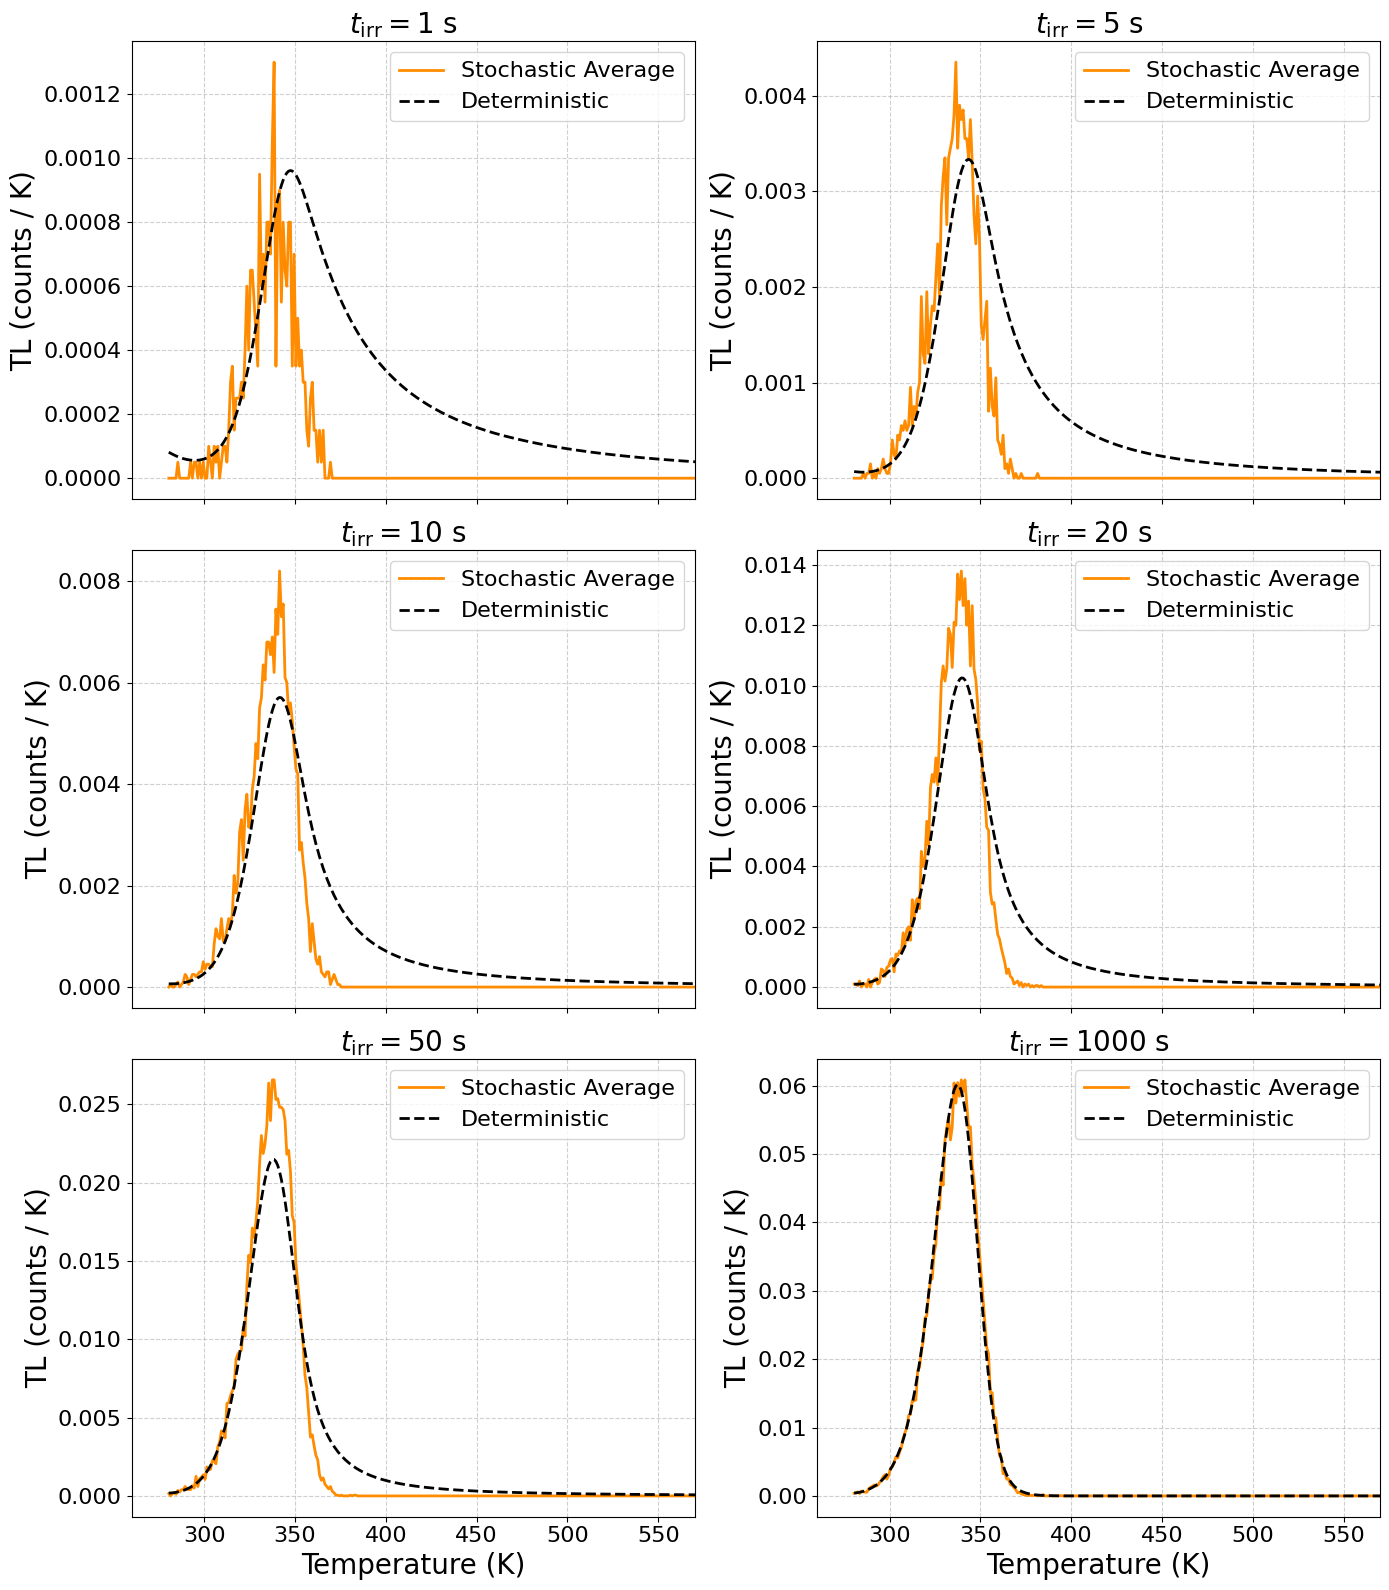

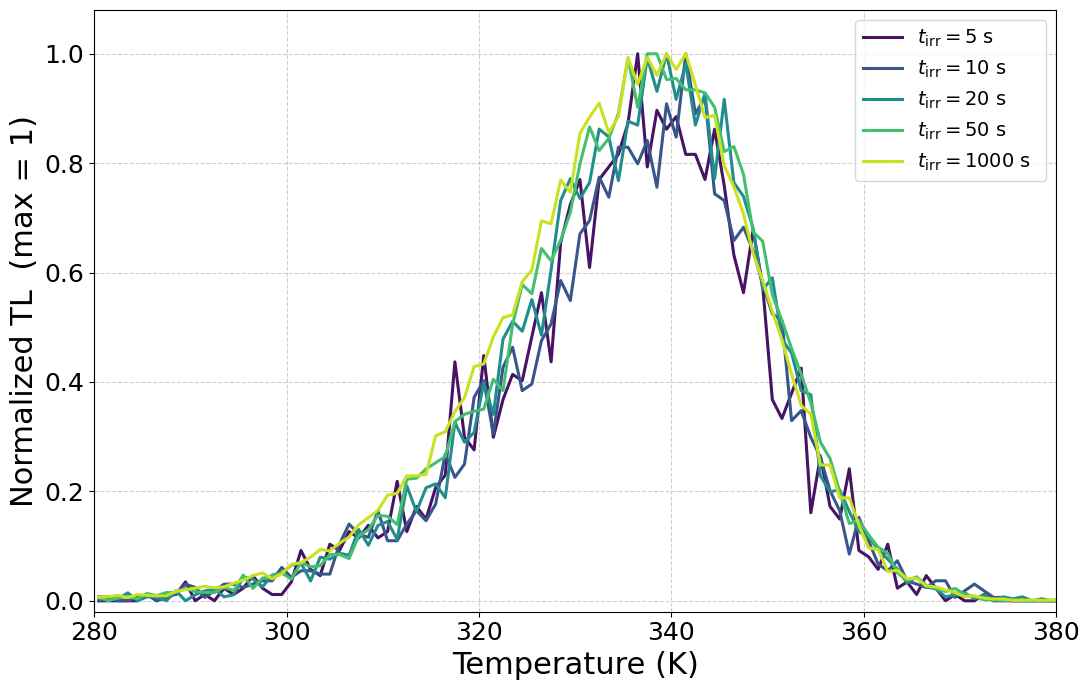

Saved -> otor_tirr_sweep_N2.npz
Total elapsed: 12.65 s


In [7]:
# -*- coding: utf-8 -*-
"""
OTOR Model — Direct Gillespie (no dt_micro).
Fixed N = 2, sweep t_irr = 1, 5, 10, 20, 50, 1000 s.

Produces a 3x2 panel of TL glow curves (stochastic mean vs. deterministic).

  Phase 1, 2 : constant propensities -> tau = -ln(u)/a0 (exact)
  Phase 3    : time-dependent a0(t)   -> tau from inverting
               Lambda(tau) = ∫ a0 dt = -ln(u) via Simpson + bisection
  Fill order : stamp [t, t_next) with pre-jump state, then jump.

num_runs(N) = round(base_runs * Nref / N)
"""

import matplotlib.pyplot as plt
from numba import njit
import numpy as np
from scipy.integrate import solve_ivp
import pickle
import time

start_time = time.time()

# --- Physical Constants ---
Nref = 5
E    = 0.87
s    = 1e12
k_B  = 8.617333e-5

# --- Protocol ---
T0         = 280.0
beta       = 1.0
t_relax    = 80.0
t_heat_max = 410.0

# --- Study ---
N_fixed      = 2
t_irr_values = [1.0, 5.0, 10.0, 20.0, 50.0, 1000.0]


# ============================================================================
# Time-dependent hazard helpers (Numba) — Phase 3
# ============================================================================
@njit(cache=True)
def _hazard_increment(t_start, tau, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub):
    """∫_0^tau a0(t_start+s) ds  via composite Simpson."""
    if tau <= 0.0:
        return 0.0
    a_const = (A_n * max(0.0, N - n) * nc
               + A_m * max(0.0, m)     * nc
               + B_m * max(0.0, N - m) * nv)
    if n_sub % 2 == 1:
        n_sub += 1
    h = tau / n_sub
    total = 0.0
    for i in range(n_sub + 1):
        tt = t_start + i * h
        T  = T0 + beta * tt
        p  = s * np.exp(-E / (k_B * T))
        val = n * p + a_const
        if i == 0 or i == n_sub:
            w = 1.0
        elif i % 2 == 1:
            w = 4.0
        else:
            w = 2.0
        total += w * val
    return total * h / 3.0


@njit(cache=True)
def _draw_heating_tau(t_start, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                      u, t_heat_max, tol, n_sub):
    """Find tau >= 0 s.t. ∫_0^tau a0(t_start+s) ds = -ln(u)."""
    target = -np.log(u)
    t_remaining = t_heat_max - t_start
    if t_remaining <= 0.0:
        return 0.0
    full = _hazard_increment(t_start, t_remaining, n, nc, m, nv,
                             A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
    if full < target:
        return t_remaining + 1.0
    lo = 0.0
    hi = t_remaining
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        hmid = _hazard_increment(t_start, mid, n, nc, m, nv,
                                 A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
        if hmid < target:
            lo = mid
        else:
            hi = mid
        if (hi - lo) < tol:
            break
    return 0.5 * (lo + hi)


@njit(cache=True)
def _select_channel(u, a1, a2, a3, a4, a5, a0):
    uu = u * a0
    if uu < a1:
        return 1
    uu -= a1
    if uu < a2:
        return 2
    uu -= a2
    if uu < a3:
        return 3
    uu -= a3
    if uu < a4:
        return 4
    return 5


# ============================================================================
# Direct-Gillespie simulator (no dt_micro), fill-order fix
# Returns only the emission-temperature list (all the glow curve needs).
# ============================================================================
@njit(cache=True)
def simulate_single_trajectory(
    N, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
    t_irr, t_relax, t_heat_max,
):
    emission_temps_buf = np.empty(N * 4 + 400, dtype=np.float64)
    emission_count = 0

    n = 0.0; nc = 0.0; m = 0.0; nv = 0.0
    p_room = s * np.exp(-E / (k_B * T0))

    # ---------------- PHASE 1: Irradiation ----------------
    t = 0.0
    while t < t_irr:
        a1 = G
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t + tau
        if t_next > t_irr:
            break

        t = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 1: nc += 1; nv += 1
        elif ch == 2: n  -= 1; nc += 1
        elif ch == 3: n  += 1; nc -= 1
        elif ch == 4: nc -= 1; m  -= 1
        else:         nv -= 1; m  += 1

    # ---------------- PHASE 2: Relaxation ----------------
    t_rel = 0.0
    while t_rel < t_relax:
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break

        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t_rel + tau
        if t_next > t_relax:
            break

        t_rel = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             0.0, a2, a3, a4, a5, a0)
        if   ch == 2: n  -= 1; nc += 1
        elif ch == 3: n  += 1; nc -= 1
        elif ch == 4: nc -= 1; m  -= 1
        else:         nv -= 1; m  += 1

    # ---------------- PHASE 3: Heating ----------------
    t_heat = 0.0
    tol    = 1e-9
    n_sub  = 16

    while t_heat < t_heat_max and (n > 0 or nc > 0 or nv > 0 or m > 0):
        T_now = T0 + beta * t_heat
        p_now = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        u   = np.random.uniform(0.0, 1.0)
        tau = _draw_heating_tau(t_heat, n, nc, m, nv,
                                A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                                u, t_heat_max, tol, n_sub)
        if t_heat + tau > t_heat_max or tau > (t_heat_max - t_heat):
            t_next = t_heat_max
        else:
            t_next = t_heat + tau

        if t_next >= t_heat_max:
            t_heat = t_heat_max
            break

        t_heat = t_next
        T_now  = T0 + beta * t_heat
        p_now  = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, 0.0, a0)
        if   ch == 1: n  -= 1; nc += 1
        elif ch == 2: n  += 1; nc -= 1
        elif ch == 3:
            nc -= 1; m  -= 1
            if emission_count < len(emission_temps_buf):
                emission_temps_buf[emission_count] = T_now
                emission_count += 1
        else:         nv -= 1; m  += 1

    return emission_temps_buf[:emission_count]


# ============================================================================
# Simulation driver for a given t_irr, fixed N
# ============================================================================
def run_simulation(t_irr_val, N_val=N_fixed, num_runs=20000, seed=42):
    A_n = 0.005 * Nref / N_val
    A_m = 0.1   * Nref / N_val
    B_m = 0.1   * Nref / N_val
    G   = 0.5   * N_val / Nref

    np.random.seed(seed)

    bin_width   = 1.0
    bins        = np.arange(T0, T0 + beta * t_heat_max + bin_width, bin_width)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    # Warm-up JIT (single throwaway run)
    _ = simulate_single_trajectory(
        N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
        t_irr_val, t_relax, t_heat_max)

    print(f"  t_irr={t_irr_val}: num_runs={num_runs}")

    all_intensities = []
    print_interval  = max(num_runs // 4, 1)

    for i in range(num_runs):
        event_temps = simulate_single_trajectory(
            N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
            t_irr_val, t_relax, t_heat_max)
        hist, _ = np.histogram(event_temps, bins=bins)
        all_intensities.append(hist / bin_width)

        if (i + 1) % print_interval == 0 or (i + 1) == num_runs:
            print(f"  t_irr={t_irr_val}: {i + 1}/{num_runs} runs. "
                  f"Elapsed: {time.time()-start_time:.2f} s")

    mean_intensity = np.mean(all_intensities, axis=0)

    # ---------------- Deterministic ODE (glow curve only) ----------------
    p_room_det = s * np.exp(-E / (k_B * T0))

    def ode_irr(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (G - n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = G - B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    sol_irr  = solve_ivp(ode_irr, [0, t_irr_val], [0.0]*4, method='LSODA')
    y0_relax = sol_irr.y[:, -1]

    def ode_relax(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    sol_relax = solve_ivp(ode_relax, [0, t_relax], y0_relax, method='LSODA')
    y0_heat   = sol_relax.y[:, -1]

    def ode_heat(t, y):
        n, nc, m, nv = y
        T = T0 + beta * t
        p = s * np.exp(-E / (k_B * T))
        dn  = -n * p + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    t_bin_eval    = np.clip((bin_centers - T0) / beta, 0, t_heat_max)
    sol_heat_bins = solve_ivp(ode_heat, [0, t_heat_max], y0_heat,
                              t_eval=t_bin_eval, method='LSODA')
    det_intensity_bins = np.array([
        A_m * max(0.0, m_val) * max(0.0, nc_val)
        for n_val, nc_val, m_val, nv_val in sol_heat_bins.y.T
    ])

    stoch_area = np.sum(mean_intensity * bin_width)
    det_area   = np.sum(det_intensity_bins * bin_width)
    diff_pct   = 100 * (stoch_area - det_area) / det_area

    print(f"  t_irr={t_irr_val}: Stoch Area={stoch_area:.4f}, "
          f"Det Area={det_area:.4f}, Rel Diff={diff_pct:.2f}%")

    return (bin_centers, mean_intensity, det_intensity_bins,
            stoch_area, det_area, diff_pct)


# ============================================================================
# Run sweep
# ============================================================================
results = {}

print('\n' + '=' * 60)
print(f'RUNNING t_irr SWEEP FOR N = {N_fixed}')
print(f'  t_irr_values = {t_irr_values}')
print('=' * 60)

for t_irr_val in t_irr_values:
    print(f'\n--- t_irr = {t_irr_val} s ---')
    results[t_irr_val] = run_simulation(t_irr_val, N_val=N_fixed,
                                        num_runs=20000, seed=42)

print('\n' + '=' * 60)
print('SUMMARY OF GLOW CURVE AREA COMPARISON')
print('=' * 60)
for t_irr_val in t_irr_values:
    diff_pct = results[t_irr_val][5]
    print(f'  t_irr = {t_irr_val:>7.1f} s: '
          f'Relative Difference = {diff_pct:>6.2f}%')
print('=' * 60)


# ============================================================================
# 3x2 panel of TL glow curves — fixed N = 2, varying t_irr
# ============================================================================
fig, axes = plt.subplots(3, 2, figsize=(14, 16), sharex=True)

for i, (ax, t_irr_val) in enumerate(zip(axes.ravel(), t_irr_values)):
    (bin_centers, mean_intensity, det_intensity_bins,
     stoch_area, det_area, diff_pct) = results[t_irr_val]

    ax.plot(
        bin_centers, mean_intensity,
        color='darkorange', lw=2,
        label='Stochastic Average',
    )
    ax.plot(
        bin_centers, det_intensity_bins,
        color='black', linestyle='--', lw=2,
        label='Deterministic',
    )

    if i in (4, 5):
        ax.set_xlabel('Temperature (K)', fontsize=20)
    ax.set_ylabel('TL (counts / K)', fontsize=20)
    ax.set_title(
        f'$t_{{\\rm irr}} = {t_irr_val:g}$ s   '
        ,
        fontsize=20,
    )
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(frameon=True, fontsize=16)
    ax.set_xlim(260, 570)
    ax.tick_params(axis='both', labelsize=16)

# plt.suptitle(
#     f'$N = {N_fixed}$ with Varying Irradiation Time\n',
#     fontsize=24,
# )
plt.tight_layout()
plt.show()

# ============================================================================
# Single plot: glow curves (t_irr = 1 s excluded), each normalized to max = 1
# ============================================================================
t_irr_norm = [t for t in t_irr_values if t != 1.0]   # drop t_irr = 1 s here only

fig_n, ax_n = plt.subplots(figsize=(11, 7))

cmap   = plt.cm.viridis
colors = cmap(np.linspace(0.05, 0.92, len(t_irr_norm)))

for color, t_irr_val in zip(colors, t_irr_norm):
    bin_centers, mean_intensity = results[t_irr_val][:2]
    peak = np.max(mean_intensity)
    norm_intensity = (mean_intensity / peak) if peak > 0 else mean_intensity
    ax_n.plot(
        bin_centers, norm_intensity,
        color=color, lw=2.2,
        label=f'$t_{{\\rm irr}} = {t_irr_val:g}$ s  '
              ,
    )

ax_n.set_xlabel('Temperature (K)', fontsize=22)
ax_n.set_ylabel('Normalized TL  (max = 1)', fontsize=22)
# ax_n.set_title(
#     f'Normalized Glow Curves — $N = {N_fixed}$, varying $t_{{\\rm irr}}$',
#     fontsize=22,
# )
ax_n.grid(True, linestyle='--', alpha=0.6)
ax_n.set_xlim(280, 380)
ax_n.set_ylim(-0.02, 1.08)
ax_n.tick_params(axis='both', labelsize=18)
ax_n.legend(frameon=True, fontsize=14, loc='upper right')
plt.tight_layout()
plt.show()
# ============================================================================
# Save data
# ============================================================================
save_dict = {
    'N_fixed':      np.array(N_fixed),
    'Nref':         np.array(Nref),
    'E':            np.array(E),
    's':            np.array(s),
    'k_B':          np.array(k_B),
    'T0':           np.array(T0),
    'beta':         np.array(beta),
    't_relax':      np.array(t_relax),
    't_heat_max':   np.array(t_heat_max),
    't_irr_values': np.array(t_irr_values),
}
for t_irr_val in t_irr_values:
    (bin_centers, mean_intensity, det_intensity_bins,
     stoch_area, det_area, diff_pct) = results[t_irr_val]
    p = f'tirr{t_irr_val:g}_'
    save_dict[p + 'bin_centers']         = bin_centers
    save_dict[p + 'mean_intensity']      = mean_intensity
    save_dict[p + 'det_intensity_bins']  = det_intensity_bins
    save_dict[p + 'stoch_area']          = np.array(stoch_area)
    save_dict[p + 'det_area']            = np.array(det_area)
    save_dict[p + 'diff_pct']            = np.array(diff_pct)

# np.savez('otor_tirr_sweep_N2.npz', **save_dict)
print("Saved -> otor_tirr_sweep_N2.npz")
print(f"Total elapsed: {time.time() - start_time:.2f} s")


DOSE-RESPONSE SWEEP: N = [2, 5, 10, 50], t_irr = [0.5, 1, 2, 5, 10, 20, 50, 100, 200, 1000]

--- N = 2 ---
  N=2, t_irr=0.5: Stoch Area=0.0135 ± 0.0005, Det Area=0.0491, Rel Diff=-72.60%
  N=2, t_irr=1: Stoch Area=0.0254 ± 0.0007, Det Area=0.0789, Rel Diff=-67.83%
  N=2, t_irr=2: Stoch Area=0.0511 ± 0.0010, Det Area=0.1183, Rel Diff=-56.82%
  N=2, t_irr=5: Stoch Area=0.1195 ± 0.0015, Det Area=0.1948, Rel Diff=-38.63%
  N=2, t_irr=10: Stoch Area=0.2227 ± 0.0019, Det Area=0.2942, Rel Diff=-24.32%
  N=2, t_irr=20: Stoch Area=0.3986 ± 0.0024, Det Area=0.4687, Rel Diff=-14.95%
  N=2, t_irr=50: Stoch Area=0.8157 ± 0.0029, Det Area=0.8661, Rel Diff=-5.82%
  N=2, t_irr=100: Stoch Area=1.2358 ± 0.0028, Det Area=1.2601, Rel Diff=-1.92%
  N=2, t_irr=200: Stoch Area=1.6294 ± 0.0023, Det Area=1.6255, Rel Diff=0.24%
  N=2, t_irr=1000: Stoch Area=1.9078 ± 0.0013, Det Area=1.8950, Rel Diff=0.68%

--- N = 5 ---
  N=5, t_irr=0.5: Stoch Area=0.0551 ± 0.0016, Det Area=0.1228, Rel Diff=-55.08%
  N=5, t_ir

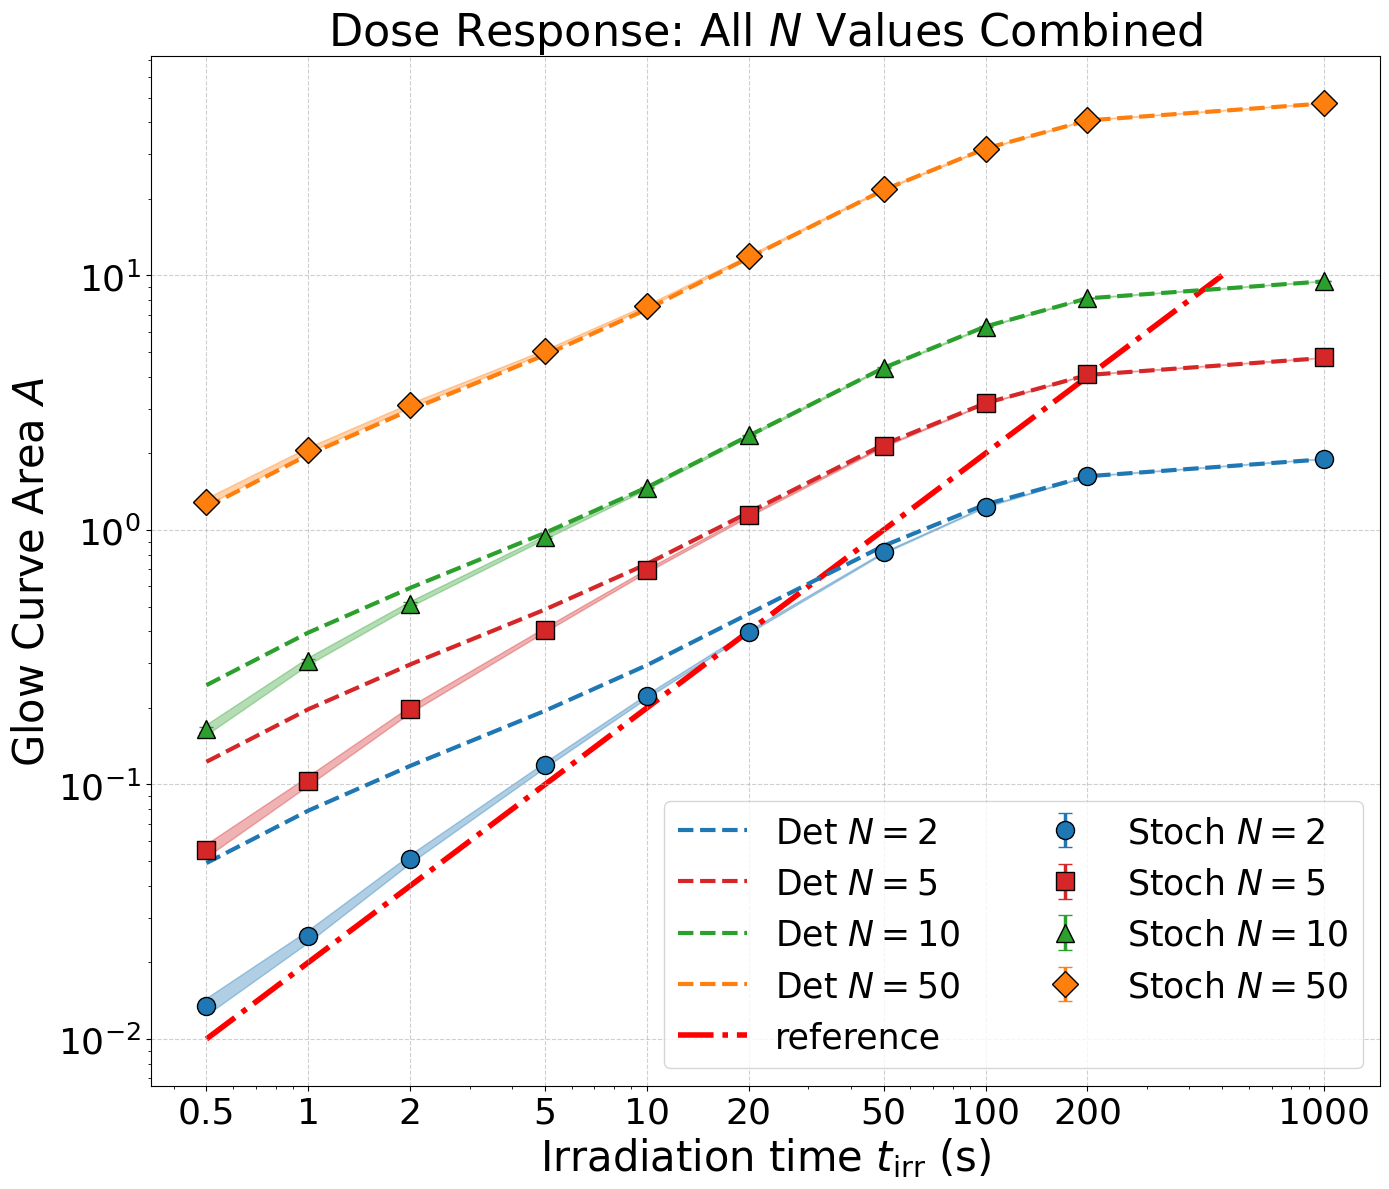

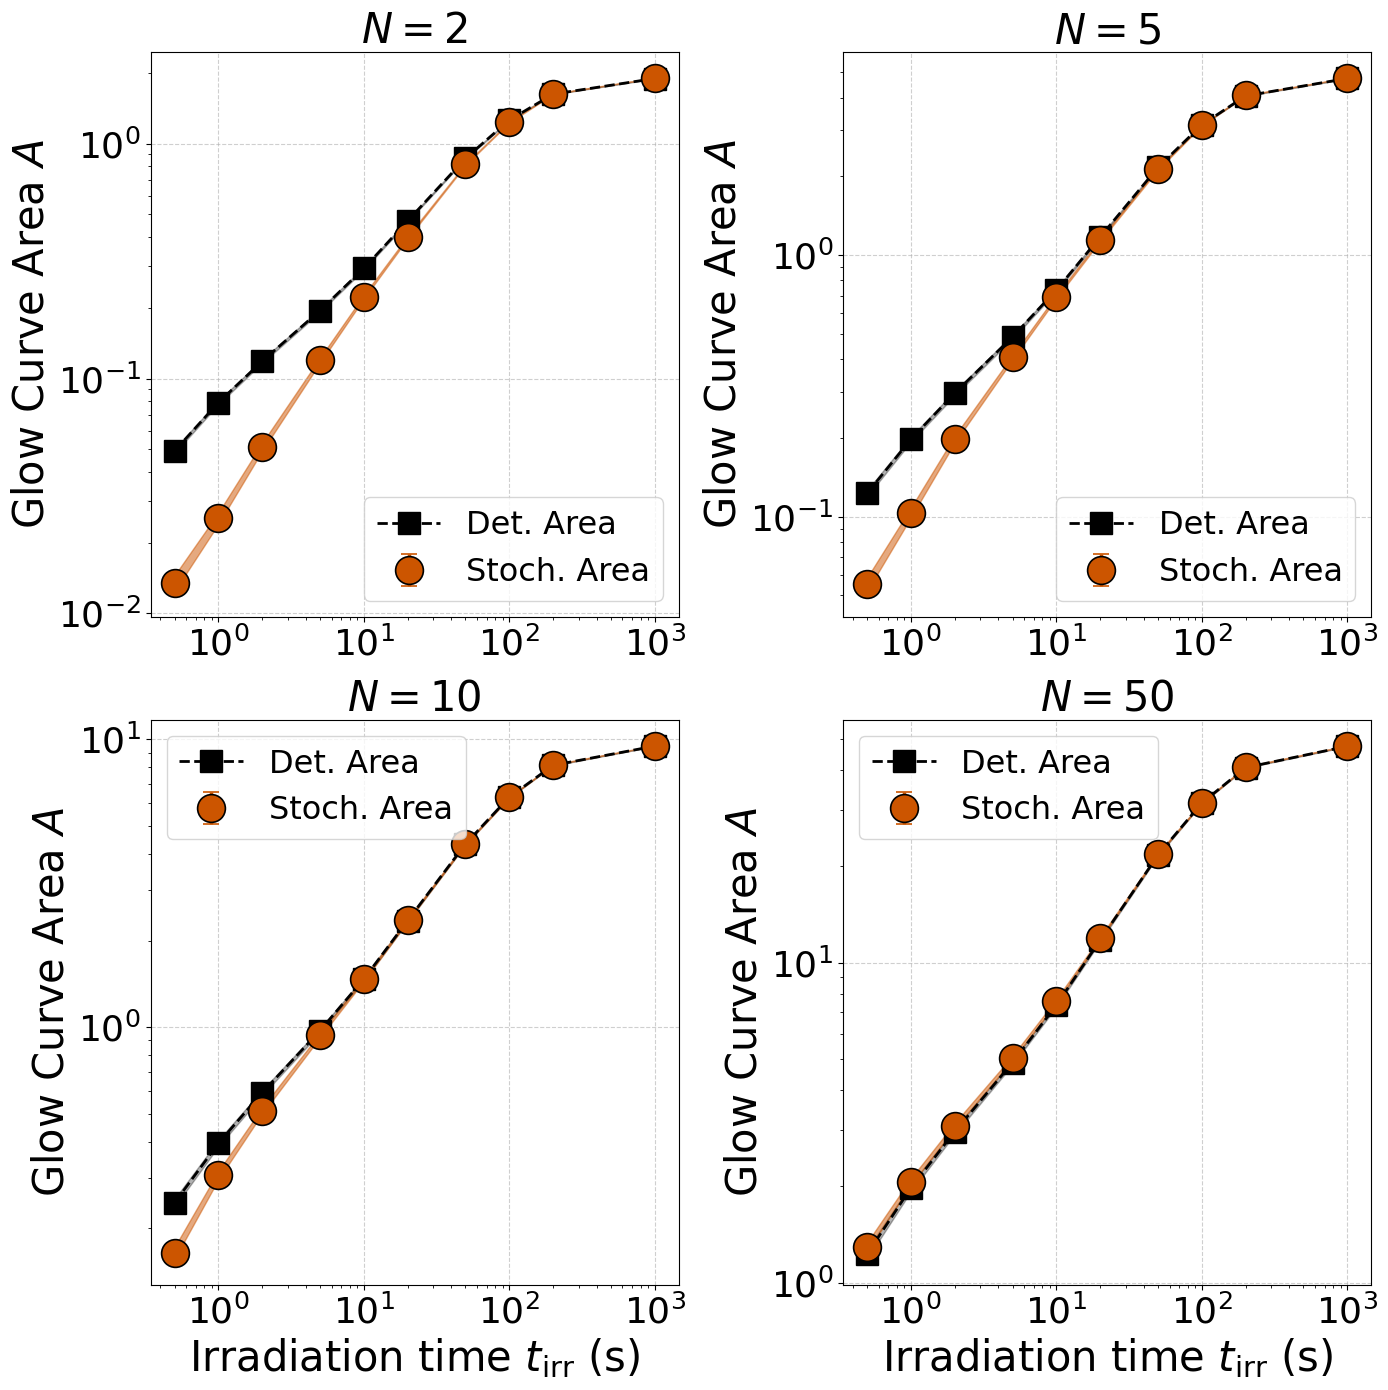


STOCHASTIC vs DETERMINISTIC AREA COMPARISON

  N = 2:
    t_irr =    0.5 s : A_stoch/A_det = 0.2740, Rel Diff = -72.60%
    t_irr =      1 s : A_stoch/A_det = 0.3217, Rel Diff = -67.83%
    t_irr =      2 s : A_stoch/A_det = 0.4318, Rel Diff = -56.82%
    t_irr =      5 s : A_stoch/A_det = 0.6137, Rel Diff = -38.63%
    t_irr =     10 s : A_stoch/A_det = 0.7568, Rel Diff = -24.32%
    t_irr =     20 s : A_stoch/A_det = 0.8505, Rel Diff = -14.95%
    t_irr =     50 s : A_stoch/A_det = 0.9418, Rel Diff =  -5.82%
    t_irr =    100 s : A_stoch/A_det = 0.9808, Rel Diff =  -1.92%
    t_irr =    200 s : A_stoch/A_det = 1.0024, Rel Diff =   0.24%
    t_irr =   1000 s : A_stoch/A_det = 1.0068, Rel Diff =   0.68%

  N = 5:
    t_irr =    0.5 s : A_stoch/A_det = 0.4492, Rel Diff = -55.08%
    t_irr =      1 s : A_stoch/A_det = 0.5248, Rel Diff = -47.52%
    t_irr =      2 s : A_stoch/A_det = 0.6664, Rel Diff = -33.36%
    t_irr =      5 s : A_stoch/A_det = 0.8343, Rel Diff = -16.57%
    t_irr =

In [9]:
# -*- coding: utf-8 -*-
"""
OTOR Model — Direct Gillespie (no dt_micro).
Dose-response: glow-curve area vs t_irr for N = 2, 5, 10, 50.

  Phase 1, 2 : constant propensities -> tau = -ln(u)/a0 (exact)
  Phase 3    : time-dependent a0(t)   -> tau from inverting
               Lambda(tau) = ∫ a0 dt = -ln(u) via Simpson + bisection
  Fill order : stamp [t, t_next) with pre-jump state, then jump.

Produces:
  - combined single panel (all N, log-log, 1:1 diagonal)
  - 2x2 panel of dose-response curves with ±2σ bands
  - dose_response_results.npz
"""

import matplotlib.pyplot as plt
from numba import njit
import numpy as np
from scipy.integrate import solve_ivp
import time

start_time = time.time()

# --- Physical Constants ---
Nref = 5
E    = 0.87
s    = 1e12
k_B  = 8.617333e-5

# --- Protocol ---
T0         = 280.0
beta       = 1.0
t_relax    = 100.0
t_heat_max = 410.0

# --- Dose-response sweep ---
t_irr_values = [0.5,1, 2, 5, 10, 20, 50, 100, 200, 1000]
N_values     = [2, 5, 10, 50]


# ============================================================================
# Hazard helpers (Phase 3)
# ============================================================================
@njit(cache=True)
def _hazard_increment(t_start, tau, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub):
    """∫_0^tau a0(t_start+s) ds  via composite Simpson."""
    if tau <= 0.0:
        return 0.0
    a_const = (A_n * max(0.0, N - n) * nc
               + A_m * max(0.0, m)     * nc
               + B_m * max(0.0, N - m) * nv)
    if n_sub % 2 == 1:
        n_sub += 1
    h = tau / n_sub
    total = 0.0
    for i in range(n_sub + 1):
        tt = t_start + i * h
        T  = T0 + beta * tt
        p  = s * np.exp(-E / (k_B * T))
        val = n * p + a_const
        if i == 0 or i == n_sub:
            w = 1.0
        elif i % 2 == 1:
            w = 4.0
        else:
            w = 2.0
        total += w * val
    return total * h / 3.0


@njit(cache=True)
def _draw_heating_tau(t_start, n, nc, m, nv,
                      A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                      u, t_heat_max, tol, n_sub):
    """Find tau >= 0 s.t. ∫_0^tau a0(t_start+s) ds = -ln(u)."""
    target = -np.log(u)
    t_remaining = t_heat_max - t_start
    if t_remaining <= 0.0:
        return 0.0
    full = _hazard_increment(t_start, t_remaining, n, nc, m, nv,
                             A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
    if full < target:
        return t_remaining + 1.0
    lo = 0.0
    hi = t_remaining
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        hmid = _hazard_increment(t_start, mid, n, nc, m, nv,
                                 A_n, A_m, B_m, N, s, E, k_B, T0, beta, n_sub)
        if hmid < target:
            lo = mid
        else:
            hi = mid
        if (hi - lo) < tol:
            break
    return 0.5 * (lo + hi)


@njit(cache=True)
def _select_channel(u, a1, a2, a3, a4, a5, a0):
    uu = u * a0
    if uu < a1:
        return 1
    uu -= a1
    if uu < a2:
        return 2
    uu -= a2
    if uu < a3:
        return 3
    uu -= a3
    if uu < a4:
        return 4
    return 5


# ============================================================================
# Direct-Gillespie simulator (no dt_micro), fill-order fix
# Returns only the emission-temperature list.
# ============================================================================
@njit(cache=True)
def simulate_single_trajectory(
    N, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
    t_irr, t_relax, t_heat_max,
):
    emission_temps_buf = np.empty(N * 4 + 400, dtype=np.float64)
    emission_count = 0

    n = 0.0; nc = 0.0; m = 0.0; nv = 0.0
    p_room = s * np.exp(-E / (k_B * T0))

    # ---------------- PHASE 1: Irradiation ----------------
    t = 0.0
    while t < t_irr:
        a1 = G
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break
        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t + tau
        if t_next > t_irr:
            break
        t = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, a5, a0)
        if   ch == 1: nc += 1; nv += 1
        elif ch == 2: n  -= 1; nc += 1
        elif ch == 3: n  += 1; nc -= 1
        elif ch == 4: nc -= 1; m  -= 1
        else:         nv -= 1; m  += 1

    # ---------------- PHASE 2: Relaxation ----------------
    t_rel = 0.0
    while t_rel < t_relax:
        a2 = n * p_room
        a3 = A_n * max(0.0, N - n) * nc
        a4 = A_m * max(0.0, m)     * nc
        a5 = B_m * max(0.0, N - m) * nv
        a0 = a2 + a3 + a4 + a5
        if a0 <= 0.0:
            break
        tau    = -np.log(np.random.uniform(0.0, 1.0)) / a0
        t_next = t_rel + tau
        if t_next > t_relax:
            break
        t_rel = t_next
        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             0.0, a2, a3, a4, a5, a0)
        if   ch == 2: n  -= 1; nc += 1
        elif ch == 3: n  += 1; nc -= 1
        elif ch == 4: nc -= 1; m  -= 1
        else:         nv -= 1; m  += 1

    # ---------------- PHASE 3: Heating ----------------
    t_heat = 0.0
    tol    = 1e-9
    n_sub  = 16

    while t_heat < t_heat_max and (n > 0 or nc > 0 or nv > 0 or m > 0):
        T_now = T0 + beta * t_heat
        p_now = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        u   = np.random.uniform(0.0, 1.0)
        tau = _draw_heating_tau(t_heat, n, nc, m, nv,
                                A_n, A_m, B_m, N, s, E, k_B, T0, beta,
                                u, t_heat_max, tol, n_sub)
        if t_heat + tau > t_heat_max or tau > (t_heat_max - t_heat):
            t_next = t_heat_max
        else:
            t_next = t_heat + tau
        if t_next >= t_heat_max:
            t_heat = t_heat_max
            break

        t_heat = t_next
        T_now  = T0 + beta * t_heat
        p_now  = s * np.exp(-E / (k_B * T_now))
        a1 = n * p_now
        a2 = A_n * max(0.0, N - n) * nc
        a3 = A_m * max(0.0, m)     * nc
        a4 = B_m * max(0.0, N - m) * nv
        a0 = a1 + a2 + a3 + a4
        if a0 <= 0.0:
            break

        ch = _select_channel(np.random.uniform(0.0, 1.0),
                             a1, a2, a3, a4, 0.0, a0)
        if   ch == 1: n  -= 1; nc += 1
        elif ch == 2: n  += 1; nc -= 1
        elif ch == 3:
            nc -= 1; m  -= 1
            if emission_count < len(emission_temps_buf):
                emission_temps_buf[emission_count] = T_now
                emission_count += 1
        else:         nv -= 1; m  += 1

    return emission_temps_buf[:emission_count]


# ============================================================================
# Simulation driver for a given (N_val, t_irr_val)
# ============================================================================
def run_simulation(N_val, t_irr_val, seed=42):
    base_runs = 20000
    num_runs  = max(int(round(base_runs * Nref / N_val)), 100)

    A_n = 0.005 * Nref / N_val
    A_m = 0.1   * Nref / N_val
    B_m = 0.1   * Nref / N_val
    G   = 0.5   * N_val / Nref

    np.random.seed(seed)

    bin_width   = 1.0
    bins        = np.arange(T0, T0 + beta * t_heat_max + bin_width, bin_width)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    # Warm-up JIT
    _ = simulate_single_trajectory(
        N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
        t_irr_val, t_relax, t_heat_max)

    # print(f"  N={N_val}, t_irr={t_irr_val:g} s  (num_runs={num_runs})")

    all_intensities = []
    print_interval  = max(num_runs // 4, 1)

    for i in range(num_runs):
        event_temps = simulate_single_trajectory(
            N_val, A_n, A_m, B_m, E, s, k_B, T0, beta, G,
            t_irr_val, t_relax, t_heat_max)
        hist, _ = np.histogram(event_temps, bins=bins)
        all_intensities.append(hist / bin_width)

        if (i +0) == num_runs:
            print(f"    N={N_val}, t_irr={t_irr_val:g}: "
                  f"{i + 1}/{num_runs} runs. "
                  f"Elapsed: {time.time()-start_time:.2f} s")

    # --- Per-trajectory areas ---
    traj_areas = np.array(
        [np.sum(intens * bin_width) for intens in all_intensities], dtype=float
    )
    stoch_area_mean = float(traj_areas.mean())
    stoch_area_sem  = float(traj_areas.std(ddof=1) / np.sqrt(len(traj_areas)))

    # ---------------- Deterministic ODE ----------------
    p_room_det = s * np.exp(-E / (k_B * T0))

    def ode_irr(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (G - n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = G - B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    sol_irr  = solve_ivp(ode_irr, [0, t_irr_val], [0.0]*4, method='LSODA')
    y0_relax = sol_irr.y[:, -1]

    def ode_relax(t, y):
        n, nc, m, nv = y
        dn  = -n * p_room_det + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p_room_det
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    sol_relax = solve_ivp(ode_relax, [0, t_relax], y0_relax, method='LSODA')
    y0_heat   = sol_relax.y[:, -1]

    def ode_heat(t, y):
        n, nc, m, nv = y
        T = T0 + beta * t
        p = s * np.exp(-E / (k_B * T))
        dn  = -n * p + A_n * max(0.0, N_val - n) * nc
        dnc = (n * p
               - A_n * max(0.0, N_val - n) * nc
               - A_m * max(0.0, m) * nc)
        dm  = -A_m * max(0.0, m) * nc + B_m * max(0.0, N_val - m) * nv
        dnv = -B_m * max(0.0, N_val - m) * nv
        return [dn, dnc, dm, dnv]

    t_bin_eval    = np.clip((bin_centers - T0) / beta, 0, t_heat_max)
    sol_heat_bins = solve_ivp(ode_heat, [0, t_heat_max], y0_heat,
                              t_eval=t_bin_eval, method='LSODA')
    det_intensity_bins = np.array([
        A_m * max(0.0, m_val) * max(0.0, nc_val)
        for n_val, nc_val, m_val, nv_val in sol_heat_bins.y.T
    ])
    det_area = float(np.sum(det_intensity_bins * bin_width))

    diff_pct = 100 * (stoch_area_mean - det_area) / det_area

    print(f"  N={N_val}, t_irr={t_irr_val:g}: "
          f"Stoch Area={stoch_area_mean:.4f} ± {stoch_area_sem:.4f}, "
          f"Det Area={det_area:.4f}, Rel Diff={diff_pct:.2f}%")

    return (stoch_area_mean, stoch_area_sem, det_area, diff_pct)


# ============================================================================
# Run dose-response sweeps
# ============================================================================
results = {N_val: {} for N_val in N_values}

print('\n' + '=' * 60)
print(f'DOSE-RESPONSE SWEEP: N = {N_values}, t_irr = {t_irr_values}')
print('=' * 60)

for N_val in N_values:
    print(f'\n--- N = {N_val} ---')
    for t_irr_val in t_irr_values:
        results[N_val][t_irr_val] = run_simulation(N_val, t_irr_val)

print('\n' + '=' * 60)
print('SUMMARY OF DOSE-RESPONSE AREAS')
print('=' * 60)
for N_val in N_values:
    print(f'\n  N = {N_val}:')
    for t_irr_val in t_irr_values:
        sm, ss, dm, dp = results[N_val][t_irr_val]
        print(f'    t_irr = {t_irr_val:>6g} s : '
              f'Stoch A = {sm:.4f} ± {ss:.4f}, Det A = {dm:.4f}, '
              f'Rel Diff = {dp:>6.2f}%')
print('=' * 60)

print(f'\nTotal elapsed time: {time.time() - start_time:.2f} s')


# ============================================================================
# Common sort order (defined BEFORE plotting)
# ============================================================================
t_arr    = np.array(t_irr_values, dtype=float)
order    = np.argsort(t_arr)
t_sorted = t_arr[order]


# ============================================================================
# Combined panel: all N together (log-log) with 1:1 diagonal
# ============================================================================
fig, ax1 = plt.subplots(figsize=(14, 12))

colors  = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e']
markers = ['o', 's', '^', 'D']

for idx, N_val in enumerate(N_values):
    sm = np.array([results[N_val][t][0] for t in t_irr_values], dtype=float)
    ss = np.array([results[N_val][t][1] for t in t_irr_values], dtype=float)
    dm = np.array([results[N_val][t][2] for t in t_irr_values], dtype=float)

    sm_s = sm[order]
    ss_s = ss[order]
    dm_s = dm[order]

    color  = colors[idx]
    marker = markers[idx]

    # Deterministic: DASHED (was solid)
    ax1.plot(t_sorted, dm_s,
             color=color, linestyle='--', lw=3,
             label=f'Det $N={N_val}$', zorder=2)

    ax1.fill_between(t_sorted,
                     sm_s - 2 * ss_s, sm_s + 2 * ss_s,
                     color=color, alpha=0.35)
    ax1.errorbar(t_sorted, sm_s, yerr=ss_s,
                 fmt=marker, color=color, ecolor=color,
                 elinewidth=2.5, capsize=5, capthick=2.5, markersize=13,
                 markeredgecolor='black', markeredgewidth=1.0,
                 label=f'Stoch $N={N_val}$')

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xticks(t_irr_values)
ax1.set_xticklabels([str(v) for v in t_irr_values])

# Reference line in data coordinates from (0.5, 0.01) to (500, 10)
ax1.plot([0.5, 500.0], [0.01, 10.0],
         color='red', linestyle='-.', lw=4,
         label='reference', zorder=1)

ax1.set_xlabel(r'Irradiation time $t_{\rm irr}$ (s)', fontsize=30)
ax1.set_ylabel('Glow Curve Area $A$', fontsize=30)
ax1.set_title('Dose Response: All $N$ Values Combined', fontsize=32)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(frameon=True, fontsize=25, ncol=2, loc='best')
ax1.tick_params(axis='both', labelsize=26)

plt.tight_layout()
plt.show()


# ============================================================================
# 2x2 panel of dose-response curves with ±2σ bands
# ============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 14), sharex=False)

for idx, (ax, N_val) in enumerate(zip(axes.ravel(), N_values)):
    sm = np.array([results[N_val][t][0] for t in t_irr_values], dtype=float)
    ss = np.array([results[N_val][t][1] for t in t_irr_values], dtype=float)
    dm = np.array([results[N_val][t][2] for t in t_irr_values], dtype=float)

    sm_s = sm[order]
    ss_s = ss[order]
    dm_s = dm[order]

    # Deterministic ±2σ band (using SEM of the stochastic run as proxy)
    ax.fill_between(t_sorted,
                    dm_s - 2 * ss_s, dm_s + 2 * ss_s,
                    color='black', alpha=0.30)
    ax.plot(t_sorted, dm_s,
            color='black', linestyle='--', lw=2,
            marker='s', markersize=16, label='Det. Area')

    # Stochastic ±2σ band + error bars
    ax.fill_between(t_sorted,
                    sm_s - 2 * ss_s, sm_s + 2 * ss_s,
                    color='#cc5500', alpha=0.50)
    ax.errorbar(t_sorted, sm_s, yerr=ss_s,
                fmt='o', color='#cc5500', ecolor='#cc5500',
                elinewidth=2.5, capsize=6, capthick=2.5, markersize=20,
                markeredgecolor='black', markeredgewidth=1.2,
                label='Stoch. Area')

    if idx >= 2:
        ax.set_xlabel(r'Irradiation time $t_{\rm irr}$ (s)', fontsize=30)
    ax.set_ylabel('Glow Curve Area $A$', fontsize=30)
    ax.set_title(f'$N={N_val}$', fontsize=30)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(frameon=True, fontsize=23)
    ax.tick_params(axis='both', labelsize=26)
    ax.set_xticks(t_irr_values)
    ax.set_xticklabels([str(v) for v in t_irr_values])
    ax.set_xscale('log')
    ax.set_yscale('log')

plt.tight_layout()
plt.show()


# ============================================================================
# Print ratio summary
# ============================================================================
print('\n' + '=' * 60)
print('STOCHASTIC vs DETERMINISTIC AREA COMPARISON')
print('=' * 60)
for N_val in N_values:
    print(f'\n  N = {N_val}:')
    for t_val in t_irr_values:
        sm, ss, dm, dp = results[N_val][t_val]
        ratio = sm / dm if dm > 0 else float('nan')
        print(f'    t_irr = {t_val:>6g} s : '
              f'A_stoch/A_det = {ratio:.4f}, '
              f'Rel Diff = {dp:>6.2f}%')
print('=' * 60)


# ============================================================================
# Save results
# ============================================================================
save_dict = {}
for N_val in N_values:
    for t_val in t_irr_values:
        sm, ss, dm, dp = results[N_val][t_val]
        save_dict[f"N{N_val}_t{t_val:g}_sm"] = sm
        save_dict[f"N{N_val}_t{t_val:g}_ss"] = ss
        save_dict[f"N{N_val}_t{t_val:g}_dm"] = dm
        save_dict[f"N{N_val}_t{t_val:g}_dp"] = dp

save_dict['N_values']     = np.array(N_values)
save_dict['t_irr_values'] = np.array(t_irr_values)

np.savez('dose_response_results.npz', **save_dict)
print("Saved results to dose_response_results.npz")
print(f"Total elapsed: {time.time() - start_time:.2f} s")